In [ ]:
import os
import subprocess

# Set Kaggle API token — paste your actual token here
os.environ['KAGGLE_API_TOKEN'] = 'YOUR_KAGGLE_API_TOKEN_HERE'

# Verify it works
result = subprocess.run(['kaggle', '--version'],
                       capture_output=True, text=True)
print(result.stdout)
print("Kaggle API configured ✅")

Kaggle CLI 2.0.1

Kaggle API configured ✅


In [2]:
!pip install timm==0.4.12 -q
!pip install einops==0.6.1 -q
!pip install decord==0.6.0 -q
!pip install gdown -q
print("All dependencies installed ✅")

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 377.0/377.0 kB 6.7 MB/s eta 0:00:00:00:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 12.2/12.2 MB 79.4 MB/s eta 0:00:00:00:010:01
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
dask-cuda 26.2.0 requires cuda-core==0.3.*, but you have cuda-core 1.0.1 which is incompatible.
dask-cuda 26.2.0 requires numba-cuda<0.23.0,>=0.22.1, but you have numba-cuda 0.30.2 which is incompatible.
distributed-ucxx-cu12 0.48.0 requires numba-cuda[cu12]<0.23.0,>=0.22.1, but you have numba-cuda 0.30.2 which is incompatible.
cuml-cu12 26.2.0 requires numba<0.62.0,>=0.60.0, but you have numba 0.65.1 which is incompatible.
cuml-cu12 26.2.0 requires numba-cuda[cu12]<0.23.0,>=0.22.1, but you have numba-cuda 0.30.2 which is incompatible.
ucxx-cu12 0.48.0 requires numba-cuda[cu12]<0.23.0,>=0.22.1, but you have numba-cuda 0.30.2 which is incompat

In [3]:
import torch
print(f"PyTorch version : {torch.__version__}")
print(f"CUDA available  : {torch.cuda.is_available()}")
print(f"GPU name        : {torch.cuda.get_device_name(0)}")
print(f"GPU memory      : {torch.cuda.get_device_properties(0).total_memory / 1e9:.1f} GB")

PyTorch version : 2.10.0+cu128
CUDA available  : True
GPU name        : Tesla T4
GPU memory      : 15.6 GB


In [4]:
import sys
import os
!git clone https://github.com/sunlicai/MAE-DFER.git
sys.path.insert(0, '/kaggle/working/MAE-DFER')
print("Repo cloned ✅")

Cloning into 'MAE-DFER'...
remote: Enumerating objects: 259, done.
remote: Counting objects: 100% (78/78), done.
remote: Compressing objects: 100% (61/61), done.
remote: Total 259 (delta 50), reused 17 (delta 17), pack-reused 181 (from 1)
Receiving objects: 100% (259/259), 16.52 MiB | 31.44 MiB/s, done.
Resolving deltas: 100% (98/98), done.
Repo cloned ✅


In [5]:
import gdown
import os

os.makedirs('/kaggle/working/weights/dfew', exist_ok=True)

fold_ids = {
    'fd1': '1wRxwEZlrc3z3DqQ84xm_olmqRsj2obH3',
    'fd2': '1lY4L2PMVWuF93K6_VqEl7QrPoSK0SvaQ',
    'fd3': '1FPKxBoGO3VXvLhcHY8iOPb9lQPi0_C1z',
    'fd4': '1yFDc1n8SaTEQWrVX8k65loQm45rfwQeO',
    'fd5': '1wmXO4M2kjpAOnvof8CmpJE6wUrxMUOgw',
}

for fold, file_id in fold_ids.items():
    out_path = f'/kaggle/working/weights/dfew/{fold}.pth'
    if os.path.exists(out_path):
        print(f"{fold}: already exists ✅")
    else:
        print(f"Downloading {fold}...")
        gdown.download(
            f'https://drive.google.com/uc?id={file_id}',
            out_path, quiet=False
        )

print("\n=== Weight files ===")
for fold in fold_ids:
    path = f'/kaggle/working/weights/dfew/{fold}.pth'
    size_mb = os.path.getsize(path) / 1e6
    print(f"{fold}: {size_mb:.0f} MB ✅")

Downloading...
From (original): https://drive.google.com/uc?id=1wRxwEZlrc3z3DqQ84xm_olmqRsj2obH3
From (redirected): https://drive.google.com/uc?id=1wRxwEZlrc3z3DqQ84xm_olmqRsj2obH3&confirm=t&uuid=8013a895-d6fe-476f-8671-2d52253c6af6
To: /kaggle/working/weights/dfew/fd1.pth
100%|██████████| 1.02G/1.02G [00:12<00:00, 83.4MB/s]


Downloading...
From (original): https://drive.google.com/uc?id=1lY4L2PMVWuF93K6_VqEl7QrPoSK0SvaQ
From (redirected): https://drive.google.com/uc?id=1lY4L2PMVWuF93K6_VqEl7QrPoSK0SvaQ&confirm=t&uuid=bd3c1caa-3ee0-4cfe-9a7c-64be63b6d77b
To: /kaggle/working/weights/dfew/fd2.pth
100%|██████████| 1.02G/1.02G [00:13<00:00, 75.7MB/s]


Downloading...
From (original): https://drive.google.com/uc?id=1FPKxBoGO3VXvLhcHY8iOPb9lQPi0_C1z
From (redirected): https://drive.google.com/uc?id=1FPKxBoGO3VXvLhcHY8iOPb9lQPi0_C1z&confirm=t&uuid=02b0b252-1a56-46b2-b68b-f53982951a6a
To: /kaggle/working/weights/dfew/fd3.pth
100%|██████████| 1.02G/1.02G [00:09<00:00, 104MB/s] 


Downloading...
From (original): https://drive.google.com/uc?id=1yFDc1n8SaTEQWrVX8k65loQm45rfwQeO
From (redirected): https://drive.google.com/uc?id=1yFDc1n8SaTEQWrVX8k65loQm45rfwQeO&confirm=t&uuid=1c36901f-7b38-4acd-a9d0-118c8a97f14f
To: /kaggle/working/weights/dfew/fd4.pth
100%|██████████| 1.02G/1.02G [00:14<00:00, 69.0MB/s]


Downloading...
From (original): https://drive.google.com/uc?id=1wmXO4M2kjpAOnvof8CmpJE6wUrxMUOgw
From (redirected): https://drive.google.com/uc?id=1wmXO4M2kjpAOnvof8CmpJE6wUrxMUOgw&confirm=t&uuid=e396d5a2-c468-4e5e-b1bd-9ef0374c473b
To: /kaggle/working/weights/dfew/fd5.pth
100%|██████████| 1.02G/1.02G [00:13<00:00, 76.3MB/s]


=== Weight files ===
fd1: 1019 MB ✅
fd2: 1019 MB ✅
fd3: 1019 MB ✅
fd4: 1019 MB ✅
fd5: 1019 MB ✅


In [6]:
import torch
import sys
from functools import partial
sys.path.insert(0, '/kaggle/working/MAE-DFER')
from modeling_finetune import VisionTransformer
import torch.nn as nn

device = torch.device('cuda')

def load_teacher(fold=1):
    model = VisionTransformer(
        img_size=160, patch_size=16,
        embed_dim=512, depth=16, num_heads=8,
        mlp_ratio=4, qkv_bias=True,
        norm_layer=partial(nn.LayerNorm, eps=1e-6),
        num_classes=7, all_frames=16, tubelet_size=2,
        drop_rate=0.0, drop_path_rate=0.0, attn_drop_rate=0.0,
        use_learnable_pos_emb=False, init_scale=0.001,
        use_mean_pooling=True, attn_type='local_global',
        lg_region_size=(2, 5, 10),
        lg_first_attn_type='self', lg_third_attn_type='cross',
        lg_attn_param_sharing_first_third=False,
        lg_attn_param_sharing_all=False,
        lg_classify_token_type='org',
        lg_no_second=False, lg_no_third=False,
    )
    ckpt_path = f'/kaggle/working/weights/dfew/fd{fold}.pth'
    checkpoint = torch.load(ckpt_path, map_location='cpu',
                            weights_only=False)
    model.load_state_dict(checkpoint['model'], strict=True)
    for param in model.parameters():
        param.requires_grad = False
    model.eval()
    model = model.to(device)
    total = sum(p.numel() for p in model.parameters()) / 1e6
    print(f"Teacher loaded — fold {fold} ✅  ({total:.1f}M params)")
    return model

teacher = load_teacher(fold=1)

==> Note: Use 'local_global' for compute reduction (lg_region_size=(2, 5, 10),lg_first_attn_type=self, lg_third_attn_type=cross,lg_attn_param_sharing_first_third=False,lg_attn_param_sharing_all=False,lg_classify_token_type=org,lg_no_second=False, lg_no_third=False)
==> Number of local regions: 8 (size=[4, 2, 1])
Teacher loaded — fold 1 ✅  (84.9M params)


In [7]:
dummy = torch.randn(2, 3, 16, 160, 160).to(device)

with torch.no_grad():
    logits            = teacher(dummy)
    logits_s2, feats  = teacher(dummy, save_feature=True)

print(f"Input shape       : {dummy.shape}")
print(f"Strategy 1 output : {logits.shape}    ← should be [2, 7]")
print(f"Strategy 2 logits : {logits_s2.shape}  ← should be [2, 7]")
print(f"Strategy 2 feature: {feats.shape}      ← should be [2, 512]")
print("\nTeacher forward pass ✅")

Input shape       : torch.Size([2, 3, 16, 160, 160])
Strategy 1 output : torch.Size([2, 7])    ← should be [2, 7]
Strategy 2 logits : torch.Size([2, 7])  ← should be [2, 7]
Strategy 2 feature: torch.Size([2, 512])      ← should be [2, 512]

Teacher forward pass ✅


In [8]:
import os
import torch
import numpy as np
from PIL import Image
from torch.utils.data import Dataset, DataLoader
import torchvision.transforms as transforms

# ── Paths ────────────────────────────────────────────────────
CLIP_BASE  = '/kaggle/input/datasets/faiqhassan98/dfew-mdata/clip_224x224_16f/clip_224x224_16f'
LABEL_BASE = '/kaggle/input/datasets/faiqhassan98/dfew-mdata'
TRAIN_CSV  = os.path.join(LABEL_BASE, 'train(single-labeled)', 'train(single-labeled)')
TEST_CSV   = os.path.join(LABEL_BASE, 'test(single-labeled)',  'test(single-labeled)')

class DFEWDataset(Dataset):
    """
    DFEW DataLoader — supports all 3 simulation scenarios:
    Sim 1: input_size  = 160 / 112 / 56 / 28
    Sim 2: num_frames  = 16 / 8 / 4 / 2
    Sim 3: controlled via MobileNetV2 width_mult in student
    """
    def __init__(self, csv_path, clip_base,
                 num_frames=16, input_size=160):
        self.clip_base  = clip_base
        self.num_frames = num_frames
        self.input_size = input_size

        self.samples = []
        with open(csv_path, 'r') as f:
            lines = f.readlines()
        for line in lines[1:]:   # skip header
            line = line.strip()
            if not line:
                continue
            parts    = line.split(',')
            clip_id  = int(parts[0])
            label    = int(parts[1]) - 1   # 1-7 → 0-6
            clip_name = f"{clip_id:05d}"
            clip_path = os.path.join(clip_base, clip_name)
            if os.path.exists(clip_path):
                self.samples.append((clip_path, label))

        self.transform = transforms.Compose([
            transforms.Resize((input_size, input_size)),
            transforms.ToTensor(),
            transforms.Normalize(mean=[0.5,0.5,0.5],
                                 std=[0.5,0.5,0.5])
        ])
        print(f"Dataset loaded: {len(self.samples)} clips | "
              f"frames={num_frames} | size={input_size}x{input_size}")

    def __len__(self):
        return len(self.samples)

    def _load_frames(self, clip_path):
        frames = sorted(
            [f for f in os.listdir(clip_path) if f.endswith('.jpg')],
            key=lambda x: int(x.replace('.jpg', ''))
        )
        indices  = np.linspace(0, len(frames)-1,
                               self.num_frames, dtype=int)
        tensors  = []
        for i in indices:
            img = Image.open(
                os.path.join(clip_path, frames[i])
            ).convert('RGB')
            tensors.append(self.transform(img))
        video = torch.stack(tensors)           # [T, C, H, W]
        video = video.permute(1, 0, 2, 3)     # [C, T, H, W]
        return video

    def __getitem__(self, idx):
        clip_path, label = self.samples[idx]
        video = self._load_frames(clip_path)
        return video, torch.tensor(label, dtype=torch.long)


def build_dataloaders(fold, num_frames=16, input_size=160,
                      batch_size=8):
    """Build train and test loaders for a given fold."""
    train_ds = DFEWDataset(
        csv_path  = os.path.join(TRAIN_CSV, f'set_{fold}.csv'),
        clip_base = CLIP_BASE,
        num_frames = num_frames,
        input_size = input_size,
    )
    test_ds = DFEWDataset(
        csv_path  = os.path.join(TEST_CSV, f'set_{fold}.csv'),
        clip_base = CLIP_BASE,
        num_frames = num_frames,
        input_size = input_size,
    )
    train_loader = DataLoader(train_ds, batch_size=batch_size,
                              shuffle=True,  num_workers=2,
                              pin_memory=True)
    test_loader  = DataLoader(test_ds,  batch_size=batch_size,
                              shuffle=False, num_workers=2,
                              pin_memory=True)
    return train_loader, test_loader

# ── Quick test with fold 1 ───────────────────────────────────
train_loader, test_loader = build_dataloaders(fold=1)
videos, labels = next(iter(train_loader))
print(f"\nBatch test:")
print(f"Video shape : {videos.shape}  ← should be [8, 3, 16, 160, 160]")
print(f"Labels shape: {labels.shape}  ← should be [8]")
print(f"Labels      : {labels}        ← values 0-6")
print(f"\nDataLoader ready ✅")

Dataset loaded: 9356 clips | frames=16 | size=160x160
Dataset loaded: 2341 clips | frames=16 | size=160x160

Batch test:
Video shape : torch.Size([8, 3, 16, 160, 160])  ← should be [8, 3, 16, 160, 160]
Labels shape: torch.Size([8])  ← should be [8]
Labels      : tensor([0, 4, 2, 2, 2, 2, 1, 4])        ← values 0-6

DataLoader ready ✅


In [9]:
import torch
import torch.nn as nn
import torchvision.models as models

class MobileNetV2GRU(nn.Module):
    def __init__(self, num_classes=7, width_mult=1.0,
                 gru_hidden=256, num_frames=16, dropout=0.3):
        super().__init__()
        self.num_frames = num_frames
        mobilenet          = models.mobilenet_v2(
            weights=None, width_mult=width_mult)
        self.backbone      = mobilenet.features
        self.backbone_out  = mobilenet.last_channel
        self.gap           = nn.AdaptiveAvgPool2d((1, 1))
        self.gru           = nn.GRU(
            input_size=self.backbone_out, hidden_size=gru_hidden,
            num_layers=1, batch_first=True)
        self.dropout       = nn.Dropout(p=dropout)
        self.classifier    = nn.Linear(gru_hidden, num_classes)
        self.frame_features = None

    def forward(self, x):
        B, C, T, H, W = x.shape
        x = x.permute(0, 2, 1, 3, 4).reshape(B*T, C, H, W)
        x = self.backbone(x)
        self.frame_features = x
        x = self.gap(x).flatten(1)
        x = x.reshape(B, T, -1)
        x, _ = self.gru(x)
        x = x[:, -1, :]
        x = self.dropout(x)
        return self.classifier(x)

student = MobileNetV2GRU(
    num_classes=7, width_mult=1.0,
    gru_hidden=256, num_frames=16, dropout=0.3
).to(device)

total = sum(p.numel() for p in student.parameters()) / 1e6
print(f"Student model built ✅  ({total:.2f}M params, dropout=0.3)")

dummy = torch.randn(2, 3, 16, 160, 160).to(device)
with torch.no_grad():
    out = student(dummy)
print(f"Output shape: {out.shape}  ← should be [2, 7]")
print("Student ready ✅")

Student model built ✅  (3.41M params, dropout=0.3)
Output shape: torch.Size([2, 7])  ← should be [2, 7]
Student ready ✅


In [10]:
import torch.nn.functional as F

class SoftLogitLoss(nn.Module):
    """Strategy 1 — Hinton et al. (2015)"""
    def __init__(self, temperature=4.0, lambda_kd=0.7):
        super().__init__()
        self.T         = temperature
        self.lambda_kd = lambda_kd
        self.ce        = nn.CrossEntropyLoss()

    def forward(self, s_logits, t_logits, labels):
        t_soft = F.softmax(t_logits / self.T, dim=1)
        s_soft = F.log_softmax(s_logits / self.T, dim=1)
        kd = F.kl_div(s_soft, t_soft,
                      reduction='batchmean') * (self.T**2)
        ce = self.ce(s_logits, labels)
        loss = self.lambda_kd * kd + (1 - self.lambda_kd) * ce
        return loss, kd.item(), ce.item()

print("Strategy 1 loss ready ✅")

Strategy 1 loss ready ✅


In [11]:
class FeatureConnector(nn.Module):
    """Bridge: student CNN features → teacher token dimension"""
    def __init__(self, student_channels=1280, teacher_dim=512,
                 num_frames=16):
        super().__init__()
        self.gap        = nn.AdaptiveAvgPool2d((1, 1))
        self.project    = nn.Linear(student_channels, teacher_dim)
        self.num_frames = num_frames  # ← used dynamically, not hardcoded

    def forward(self, student_feat):
        x = self.gap(student_feat).flatten(1)      # [B*T, C]
        B_T, C = x.shape
        B = B_T // self.num_frames                 # ← uses self.num_frames
        x = x.reshape(B, self.num_frames, C).mean(dim=1)  # [B, C]
        return self.project(x)                     # [B, 512]


class FeatureTransferLoss(nn.Module):
    """Strategy 2 — Romero et al. (2015) — FitNets"""
    def __init__(self, student_channels=1280,
                 teacher_dim=512, lambda_hint=0.5,
                 num_frames=16):
        super().__init__()
        self.connector   = FeatureConnector(
            student_channels, teacher_dim, num_frames)
        self.lambda_hint = lambda_hint
        self.ce          = nn.CrossEntropyLoss()

    def forward(self, s_logits, s_feat, t_feat, labels):
        s_aligned = self.connector(s_feat)
        hint = F.mse_loss(s_aligned, t_feat.detach())
        ce   = self.ce(s_logits, labels)
        loss = self.lambda_hint * hint + (1-self.lambda_hint) * ce
        return loss, hint.item(), ce.item()

print("Strategy 2 loss ready ✅")

Strategy 2 loss ready ✅


In [12]:
class TaskSpecificLoss(nn.Module):
    """Strategy 3 — Zagoruyko & Komodakis (2017) + Ma et al. (2023)"""
    def __init__(self, lambda_at=1.0, lambda_compact=0.5,
                 num_frames=16):          # ← added num_frames
        super().__init__()
        self.lambda_at      = lambda_at
        self.lambda_compact = lambda_compact
        self.ce             = nn.CrossEntropyLoss()
        self.num_frames     = num_frames  # ← stored, not hardcoded

    def _attn_map(self, feat):
        attn = feat.pow(2).sum(dim=1)    # [B, H, W]
        B, H, W = attn.shape
        return F.normalize(attn.reshape(B, -1), p=2, dim=1)

    def _at_loss(self, t_feat, s_feat):
        B_T, C, H_s, W_s = s_feat.shape
        T  = self.num_frames             # ← dynamic, not hardcoded
        N  = 8
        B  = B_T // T

        # Student attention map
        s      = s_feat.reshape(B, T, C, H_s, W_s).mean(1)
        s_attn = self._attn_map(s)

        # Teacher attention map from hook [B*N, S, 512]
        BN, S, D = t_feat.shape
        B_t = BN // N
        t   = t_feat[:, 1:, :].reshape(B_t, N, -1, D).mean(2).mean(1)
        t_spatial = t.unsqueeze(-1).unsqueeze(-1).expand(
            B_t, D, H_s, W_s)
        t_attn = self._attn_map(t_spatial)

        return F.mse_loss(s_attn, t_attn.detach())

    def _compact_loss(self, s_logits, labels):
        B, C = s_logits.shape
        mask = torch.zeros_like(s_logits)
        mask.scatter_(1, labels.unsqueeze(1), 1.0)
        u = (torch.ones_like(s_logits) / (C-1)) * (1-mask)
        p = F.softmax(s_logits, dim=1) * (1-mask)
        p = p.clamp(min=1e-8)
        u = u.clamp(min=1e-8)
        kl1 = (p * (p/u).log()).sum(1).mean()
        kl2 = (u * (u/p).log()).sum(1).mean()
        return (kl1 + kl2) * 0.5

    def forward(self, s_logits, s_feat, t_inter, labels):
        ce      = self.ce(s_logits, labels)
        at      = self._at_loss(t_inter, s_feat)
        compact = self._compact_loss(s_logits, labels)
        loss    = self.lambda_at*at + self.lambda_compact*compact + ce
        return loss, at.item(), compact.item(), ce.item()

print("Strategy 3 loss ready ✅")

Strategy 3 loss ready ✅


In [13]:
import torch.optim as optim
from collections import defaultdict


def train_one_epoch(student, teacher, loader, optimizer,
                    criterion, strategy, device,
                    hook_output=None):
    student.train()
    teacher.eval()
    total_loss, correct, total = 0.0, 0, 0

    for videos, labels in loader:
        videos = videos.to(device)
        labels = labels.to(device)
        optimizer.zero_grad()

        with torch.no_grad():
            if strategy == 2:
                t_logits, t_feat = teacher(videos, save_feature=True)
            else:
                t_logits = teacher(videos)

        s_logits = student(videos)

        if strategy == 1:
            loss, _, _ = criterion(s_logits, t_logits, labels)
        elif strategy == 2:
            loss, _, _ = criterion(s_logits,
                                   student.frame_features,
                                   t_feat, labels)
        elif strategy == 3:
            loss, _, _, _ = criterion(s_logits,
                                      student.frame_features,
                                      hook_output['feat'], labels)

        loss.backward()
        optimizer.step()

        total_loss += loss.item()
        correct    += (s_logits.argmax(1) == labels).sum().item()
        total      += labels.size(0)

    return total_loss / len(loader), correct / total * 100


def evaluate(student, loader, device):
    student.eval()
    preds_all, labels_all = [], []

    with torch.no_grad():
        for videos, labels in loader:
            videos = videos.to(device)
            preds  = student(videos).argmax(1).cpu()
            preds_all.extend(preds.tolist())
            labels_all.extend(labels.tolist())

    war = sum(p==l for p,l in zip(preds_all,labels_all)) \
          / len(labels_all) * 100

    cc, ct = defaultdict(int), defaultdict(int)
    for p, l in zip(preds_all, labels_all):
        ct[l] += 1
        cc[l] += int(p == l)
    uar = sum(cc[c]/ct[c] for c in ct) / len(ct) * 100

    return uar, war


print("Training functions ready ✅")

Training functions ready ✅


In [14]:
import shutil
import os
import subprocess
import json

WORK_DIR    = '/kaggle/working'
CKPT_DIR    = '/kaggle/working/checkpoints'
DATASET_DIR = '/kaggle/working/dataset_upload'
DATASET_ID  = 'faiqhassan98/kd-fer-checkpoints'

os.makedirs(CKPT_DIR, exist_ok=True)
os.makedirs(DATASET_DIR, exist_ok=True)

def permanent_save(src_path):
    fname = os.path.basename(src_path)
    dst   = f'{WORK_DIR}/{fname}'
    shutil.copy2(src_path, dst)
    print(f"Saved: {dst} ✅")

def push_to_dataset(strategy=None, fold=None):
    os.makedirs(DATASET_DIR, exist_ok=True)

    # Clear upload folder
    for fname in os.listdir(DATASET_DIR):
        if fname not in ['dataset-metadata.json', 'readme.txt']:
            try:
                os.remove(os.path.join(DATASET_DIR, fname))
            except:
                pass

    # Step 1 — copy ALL .pth files from /kaggle/working/ root
    # This includes current AND any previous folds still in working
    count = 0
    for fname in os.listdir(WORK_DIR):
        if fname.endswith('.pth'):
            shutil.copy2(
                os.path.join(WORK_DIR, fname),
                os.path.join(DATASET_DIR, fname)
            )
            count += 1

    # Step 2 — copy existing files from mounted dataset
    # This recovers any previous folds already pushed
    dataset_path = '/kaggle/input/datasets/faiqhassan98/kd-fer-checkpoints'
    if os.path.exists(dataset_path):
        for fname in os.listdir(dataset_path):
            if fname.endswith('.pth'):
                dst = os.path.join(DATASET_DIR, fname)
                if not os.path.exists(dst):
                    shutil.copy2(
                        os.path.join(dataset_path, fname),
                        dst
                    )
                    count += 1

    if count == 0:
        print("No checkpoints to push ❌")
        return

    meta = {
        "title": "kd-fer-checkpoints",
        "id": DATASET_ID,
        "licenses": [{"name": "CC0-1.0"}]
    }
    with open(f'{DATASET_DIR}/dataset-metadata.json', 'w') as f:
        json.dump(meta, f)

    print(f"Pushing {count} total files...")
    result = subprocess.run(
        ['kaggle', 'datasets', 'version',
         '-p', DATASET_DIR,
         '-m', f's{strategy}_fold{fold}',
         '--dir-mode', 'zip'],
        capture_output=True, text=True,
        timeout=300
    )

    if result.returncode == 0:
        print(f"Pushed {count} files to dataset ✅")
        # List what is now in dataset
        for f in sorted(os.listdir(DATASET_DIR)):
            if f.endswith('.pth'):
                print(f"  {f}")
    else:
        print(f"Push failed ❌")
        print(result.stderr[:200])


def restore_from_dataset():
    """Restore checkpoints from Kaggle Dataset at session start."""
    dataset_path = '/kaggle/input/datasets/faiqhassan98/kd-fer-checkpoints'

    if not os.path.exists(dataset_path):
        print("No dataset mounted — starting fresh")
        return

    files = [f for f in os.listdir(dataset_path)
             if f.endswith('.pth')]

    if not files:
        print("Dataset empty — no checkpoints to restore")
        return

    restored = 0
    for fname in files:
        src = os.path.join(dataset_path, fname)
        dst = os.path.join(WORK_DIR, fname)
        if not os.path.exists(dst):
            shutil.copy2(src, dst)
            restored += 1

    print(f"Restored {restored} checkpoints from dataset ✅")
    for f in sorted(files):
        print(f"  {f}")

print("Checkpoint system ready ✅")

Checkpoint system ready ✅


In [ ]:
import os

# ── Restore checkpoints from permanent dataset ────────────────
restore_from_dataset()

# ══════════════════════════════════════════════════
# CHANGE ONLY THESE TWO VALUES FOR EACH RUN
STRATEGY   = 3   # 1, 2, or 3
FOLD       = 5  # 1, 2, 3, 4, or 5
# ══════════════════════════════════════════════════

NUM_EPOCHS = 30
BATCH_SIZE = 8
CKPT_DIR   = '/kaggle/working/checkpoints'
CKPT_PATH  = f'{CKPT_DIR}/student_s{STRATEGY}_fold{FOLD}.pth'
BEST_PATH  = f'{CKPT_DIR}/student_s{STRATEGY}_fold{FOLD}_best.pth'

os.makedirs(CKPT_DIR, exist_ok=True)

# ── Reload teacher for correct fold ───────────────
teacher = load_teacher(fold=FOLD)

# ── Build DataLoader for correct fold ─────────────
train_loader, test_loader = build_dataloaders(fold=FOLD,
                                               batch_size=BATCH_SIZE)

# ── Build student ──────────────────────────────────
student = MobileNetV2GRU(
    num_classes=7, width_mult=1.0,
    gru_hidden=256, num_frames=16, dropout=0.3
).to(device)

optimizer   = optim.Adam(student.parameters(), lr=1e-4)
start_epoch = 0
best_uar    = 0.0

# ── Restore checkpoint if exists ──────────────────
PERM_CKPT = f'/kaggle/working/student_s{STRATEGY}_fold{FOLD}.pth'
if os.path.exists(PERM_CKPT) and not os.path.exists(CKPT_PATH):
    shutil.copy2(PERM_CKPT, CKPT_PATH)
    print("Checkpoint restored from permanent storage ✅")

if os.path.exists(CKPT_PATH):
    ckpt = torch.load(CKPT_PATH, map_location=device,
                      weights_only=False)
    student.load_state_dict(ckpt['model'])
    optimizer.load_state_dict(ckpt['optimizer'])
    start_epoch = ckpt['epoch'] + 1
    best_uar    = ckpt.get('best_uar', 0.0)
    print(f"Resumed from epoch {start_epoch} ✅")
    print(f"Previous best UAR: {best_uar:.2f}%")
else:
    print("No checkpoint found — starting fresh")

# ── Select criterion based on strategy ────────────
if STRATEGY == 1:
    criterion = SoftLogitLoss(temperature=4.0, lambda_kd=0.7)
    hook_output = None
elif STRATEGY == 2:
    criterion = FeatureTransferLoss(
        student_channels=student.backbone_out,
        teacher_dim=512, lambda_hint=0.5, num_frames=16
    ).to(device)
    hook_output = None
elif STRATEGY == 3:
    criterion = TaskSpecificLoss(
        lambda_at=1.0, lambda_compact=0.5
    ).to(device)
    hook_output = {}
    def hook_fn(module, input, output):
        hook_output['feat'] = output
    hook = teacher.blocks[8].register_forward_hook(hook_fn)

print(f"\nStarting Strategy {STRATEGY}, Fold {FOLD}")
print(f"Epochs: {start_epoch+1} to {NUM_EPOCHS}")
print("=" * 50)

# ── Training loop ──────────────────────────────────
for epoch in range(start_epoch, NUM_EPOCHS):

    train_loss, train_acc = train_one_epoch(
        student, teacher, train_loader, optimizer,
        criterion, STRATEGY, device, hook_output
    )
    uar, war = evaluate(student, test_loader, device)

    is_best = uar > best_uar
    if is_best:
        best_uar = uar

    print(f"Epoch {epoch+1:02d}/{NUM_EPOCHS} | "
          f"Loss: {train_loss:.4f} | "
          f"Acc: {train_acc:.1f}% | "
          f"UAR: {uar:.2f}% | "
          f"WAR: {war:.2f}%"
          + (" ⭐" if is_best else ""))

    # Save every epoch
    torch.save({
        'epoch': epoch, 'model': student.state_dict(),
        'optimizer': optimizer.state_dict(),
        'uar': uar, 'war': war, 'best_uar': best_uar,
    }, CKPT_PATH)
    permanent_save(CKPT_PATH)

    if is_best:
        torch.save({
            'epoch': epoch, 'model': student.state_dict(),
            'uar': uar, 'war': war,
        }, BEST_PATH)
        permanent_save(BEST_PATH)


# ── Remove hook if Strategy 3 ──────────────────────
if STRATEGY == 3:
    hook.remove()

print(f"\nBest UAR: {best_uar:.2f}%")
print(f"Best model: {BEST_PATH}")
print("Training complete ✅")

# Push all checkpoints to permanent dataset
push_to_dataset(strategy=STRATEGY, fold=FOLD)

In [15]:
import os, shutil, json, subprocess
import torch
import torch.nn as nn
import torch.optim as optim
import torch.nn.functional as F
from collections import defaultdict

# ══════════════════════════════════════════════════════════════
# SIMULATION CONFIG — CHANGE ONLY THESE TWO VALUES EACH RUN
# ══════════════════════════════════════════════════════════════

SIM       = 3      # 1 = Input Downsampling
                   # 2 = Reduced Frame Sampling
                   # 3 = Constrained Runtime

SIM_LEVEL = 0.5      # SIM 1 → 112, 56, 28        (px)
                   # SIM 2 → 8, 4, 2             (frames)
                   # SIM 3 → 0.75, 0.5           (alpha)

# ══════════════════════════════════════════════════════════════
# DO NOT CHANGE ANYTHING BELOW THIS LINE
# ══════════════════════════════════════════════════════════════

FOLD        = 1
NUM_EPOCHS  = 30
BATCH_SIZE  = 8
DATASET_ID  = 'faiqhassan98/kd-fer-checkpoints'
DATASET_DIR = '/kaggle/working/dataset_upload'
WORK_DIR    = '/kaggle/working'
DATASET_PATH = '/kaggle/input/datasets/faiqhassan98/kd-fer-checkpoints'

# ── Derive config from SIM and SIM_LEVEL ─────────────────────
if SIM == 1:
    INPUT_SIZE  = int(SIM_LEVEL)
    NUM_FRAMES  = 16
    WIDTH_MULT  = 1.0
    sim_tag     = f'sim1_{SIM_LEVEL}'

elif SIM == 2:
    INPUT_SIZE  = 160
    NUM_FRAMES  = int(SIM_LEVEL)    # 8, 4, or 2
    WIDTH_MULT  = 1.0
    sim_tag     = f'sim2_{SIM_LEVEL}f'

elif SIM == 3:
    INPUT_SIZE  = 160
    NUM_FRAMES  = 16
    WIDTH_MULT  = float(SIM_LEVEL)  # 0.75 or 0.5
    sim_tag     = f'sim3_{str(SIM_LEVEL).replace(".", "")}'

CKPT_DIR  = '/kaggle/working/checkpoints'
CKPT_PATH = f'{CKPT_DIR}/student_s1_{sim_tag}.pth'
BEST_PATH = f'{CKPT_DIR}/student_s1_{sim_tag}_best.pth'
os.makedirs(CKPT_DIR, exist_ok=True)

print(f"=== Simulation {SIM} — Level {SIM_LEVEL} ===")
print(f"  Input size  : {INPUT_SIZE}x{INPUT_SIZE}")
print(f"  Num frames  : {NUM_FRAMES}")
print(f"  Width mult  : {WIDTH_MULT}")
print(f"  Checkpoint  : student_s1_{sim_tag}")
print(f"{'='*50}")

# ── Restore all existing checkpoints from dataset ─────────────
restore_from_dataset()

# ── Load teacher — ALWAYS fold 1, ALWAYS 160px, ALWAYS 16f ───
teacher = load_teacher(fold=FOLD)

# ── Build DataLoader(s) ───────────────────────────────────────
# RULE: Teacher ALWAYS receives 160px AND 16 frames
# SIM 1: student gets fewer pixels  → needs separate teacher loader (160px)
# SIM 2: student gets fewer frames  → needs separate teacher loader (16f)
# SIM 3: student gets smaller model → same loader fine (both 160px/16f)

if SIM == 1:
    train_loader, test_loader = build_dataloaders(
        fold=FOLD, num_frames=NUM_FRAMES,
        input_size=INPUT_SIZE, batch_size=BATCH_SIZE
    )
    train_loader_teacher, _ = build_dataloaders(
        fold=FOLD, num_frames=16,          # teacher always 16 frames
        input_size=160, batch_size=BATCH_SIZE  # teacher always 160px
    )
    print(f"Student loader : {INPUT_SIZE}x{INPUT_SIZE}, {NUM_FRAMES} frames")
    print(f"Teacher loader : 160x160, 16 frames (always)")

elif SIM == 2:
    # ← FIXED: SIM 2 also needs separate teacher loader
    train_loader, test_loader = build_dataloaders(
        fold=FOLD, num_frames=NUM_FRAMES,  # student: 8/4/2 frames
        input_size=160, batch_size=BATCH_SIZE
    )
    train_loader_teacher, _ = build_dataloaders(
        fold=FOLD, num_frames=16,          # teacher always 16 frames
        input_size=160, batch_size=BATCH_SIZE
    )
    print(f"Student loader : 160x160, {NUM_FRAMES} frames")
    print(f"Teacher loader : 160x160, 16 frames (always)")

elif SIM == 3:
    # SIM 3: only width_mult changes — same loader fine
    train_loader, test_loader = build_dataloaders(
        fold=FOLD, num_frames=16,
        input_size=160, batch_size=BATCH_SIZE
    )
    train_loader_teacher = None
    print(f"Student loader : 160x160, 16 frames")
    print(f"Teacher loader : same (SIM 3 only changes width_mult)")

# ── Build student model ───────────────────────────────────────
student = MobileNetV2GRU(
    num_classes=7,
    width_mult=WIDTH_MULT,
    gru_hidden=256,
    num_frames=NUM_FRAMES,  # SIM 2: 8/4/2 | SIM 1&3: 16
    dropout=0.3
).to(device)

total_params = sum(p.numel() for p in student.parameters()) / 1e6
print(f"Student params : {total_params:.2f}M  (width_mult={WIDTH_MULT})")

# ── Strategy 1 loss ───────────────────────────────────────────
criterion = SoftLogitLoss(temperature=4.0, lambda_kd=0.7)

# ── Optimizer and resume state ────────────────────────────────
optimizer   = optim.Adam(student.parameters(), lr=1e-4)
start_epoch = 0
best_uar    = 0.0

PERM_CKPT = f'{WORK_DIR}/student_s1_{sim_tag}.pth'
if os.path.exists(PERM_CKPT) and not os.path.exists(CKPT_PATH):
    shutil.copy2(PERM_CKPT, CKPT_PATH)
    print(f"Checkpoint restored from working dir ✅")

if os.path.exists(CKPT_PATH):
    ckpt = torch.load(CKPT_PATH, map_location=device, weights_only=False)
    student.load_state_dict(ckpt['model'])
    optimizer.load_state_dict(ckpt['optimizer'])
    start_epoch = ckpt['epoch'] + 1
    best_uar    = ckpt.get('best_uar', 0.0)
    print(f"Resumed from epoch {start_epoch} | best UAR: {best_uar:.2f}%")
else:
    print("No checkpoint found — starting fresh")

print(f"\nStarting Sim {SIM} Level {SIM_LEVEL}")
print(f"Epochs: {start_epoch+1} to {NUM_EPOCHS}")
print("=" * 50)

# ── Training loop ─────────────────────────────────────────────
# SIM 1 and SIM 2: use separate loaders — teacher always gets
#                  160px AND 16 frames via train_loader_teacher
# SIM 3:           single loader — teacher and student share tensor

for epoch in range(start_epoch, NUM_EPOCHS):

    student.train()
    teacher.eval()
    total_loss, correct, total = 0.0, 0, 0

    if SIM == 1 or SIM == 2:
        # ← FIXED: SIM 2 now uses same two-loader path as SIM 1
        for (videos_s, labels), (videos_t, _) in zip(
                train_loader, train_loader_teacher):
            videos_s = videos_s.to(device)   # student input
            videos_t = videos_t.to(device)   # teacher input (always 16f/160px)
            labels   = labels.to(device)

            optimizer.zero_grad()
            with torch.no_grad():
                t_logits = teacher(videos_t)  # teacher gets correct shape
            s_logits = student(videos_s)      # student gets sim constraint
            loss, _, _ = criterion(s_logits, t_logits, labels)
            loss.backward()
            optimizer.step()

            total_loss += loss.item()
            correct    += (s_logits.argmax(1) == labels).sum().item()
            total      += labels.size(0)

    else:
        # SIM 3 only — same tensor safe because both get 16f/160px
        for videos, labels in train_loader:
            videos = videos.to(device)
            labels = labels.to(device)

            optimizer.zero_grad()
            with torch.no_grad():
                t_logits = teacher(videos)
            s_logits = student(videos)
            loss, _, _ = criterion(s_logits, t_logits, labels)
            loss.backward()
            optimizer.step()

            total_loss += loss.item()
            correct    += (s_logits.argmax(1) == labels).sum().item()
            total      += labels.size(0)

    train_acc  = correct / total * 100
    train_loss = total_loss / len(train_loader)

    uar, war = evaluate(student, test_loader, device)

    is_best = uar > best_uar
    if is_best:
        best_uar = uar

    print(f"Epoch {epoch+1:02d}/{NUM_EPOCHS} | "
          f"Loss: {train_loss:.4f} | "
          f"Acc: {train_acc:.1f}% | "
          f"UAR: {uar:.2f}% | "
          f"WAR: {war:.2f}%"
          + (" ⭐" if is_best else ""))

    torch.save({
        'epoch': epoch, 'model': student.state_dict(),
        'optimizer': optimizer.state_dict(),
        'uar': uar, 'war': war, 'best_uar': best_uar,
    }, CKPT_PATH)
    permanent_save(CKPT_PATH)

    if is_best:
        torch.save({
            'epoch': epoch, 'model': student.state_dict(),
            'uar': uar, 'war': war,
        }, BEST_PATH)
        permanent_save(BEST_PATH)

print(f"\nBest UAR : {best_uar:.2f}%")
print(f"Sim tag  : student_s1_{sim_tag}")
print("Training complete ✅")

# ── Push all files to dataset ─────────────────────────────────
os.makedirs(DATASET_DIR, exist_ok=True)

for fname in os.listdir(DATASET_DIR):
    if fname not in ['dataset-metadata.json']:
        try: os.remove(os.path.join(DATASET_DIR, fname))
        except: pass

if os.path.exists(DATASET_PATH):
    for fname in os.listdir(DATASET_PATH):
        if fname.endswith('.pth') or fname.endswith('.png'):
            shutil.copy2(
                os.path.join(DATASET_PATH, fname),
                os.path.join(DATASET_DIR, fname))

CKPT_SRC = '/kaggle/working/checkpoints'
if os.path.exists(CKPT_SRC):
    for fname in os.listdir(CKPT_SRC):
        if fname.endswith('.pth'):
            shutil.copy2(
                os.path.join(CKPT_SRC, fname),
                os.path.join(DATASET_DIR, fname))

for fname in os.listdir(WORK_DIR):
    if fname.endswith('.pth'):
        shutil.copy2(os.path.join(WORK_DIR, fname),
                     os.path.join(DATASET_DIR, fname))

total_files = len([f for f in os.listdir(DATASET_DIR)
                   if f.endswith('.pth') or f.endswith('.png')])
print(f"Files queued: {total_files}")
for f in sorted(os.listdir(DATASET_DIR)):
    if f.endswith('.pth') or f.endswith('.png'):
        print(f"  {f}")

meta = {
    "title": "kd-fer-checkpoints",
    "id": DATASET_ID,
    "licenses": [{"name": "CC0-1.0"}]
}
with open(f'{DATASET_DIR}/dataset-metadata.json', 'w') as f:
    json.dump(meta, f)

result = subprocess.run(
    ['kaggle', 'datasets', 'version',
     '-p', DATASET_DIR,
     '-m', f's1_{sim_tag}',
     '--dir-mode', 'zip'],
    capture_output=True, text=True, timeout=300
)
if result.returncode == 0:
    print(f"Pushed {total_files} files to dataset ✅")
else:
    print("Push failed ❌")
    print(result.stderr[:200])

=== Simulation 3 — Level 0.5 ===
  Input size  : 160x160
  Num frames  : 16
  Width mult  : 0.5
  Checkpoint  : student_s1_sim3_05
Restored 14 checkpoints from dataset ✅
  student_s1_sim1_112.pth
  student_s1_sim1_112_best.pth
  student_s1_sim1_28.pth
  student_s1_sim1_28_best.pth
  student_s1_sim1_56.pth
  student_s1_sim1_56_best.pth
  student_s1_sim2_2f.pth
  student_s1_sim2_2f_best.pth
  student_s1_sim2_4f.pth
  student_s1_sim2_4f_best.pth
  student_s1_sim2_8f.pth
  student_s1_sim2_8f_best.pth
  student_s1_sim3_075.pth
  student_s1_sim3_075_best.pth
==> Note: Use 'local_global' for compute reduction (lg_region_size=(2, 5, 10),lg_first_attn_type=self, lg_third_attn_type=cross,lg_attn_param_sharing_first_third=False,lg_attn_param_sharing_all=False,lg_classify_token_type=org,lg_no_second=False, lg_no_third=False)
==> Number of local regions: 8 (size=[4, 2, 1])
Teacher loaded — fold 1 ✅  (84.9M params)
Dataset loaded: 9356 clips | frames=16 | size=160x160
Dataset loaded: 2341 clips | fr

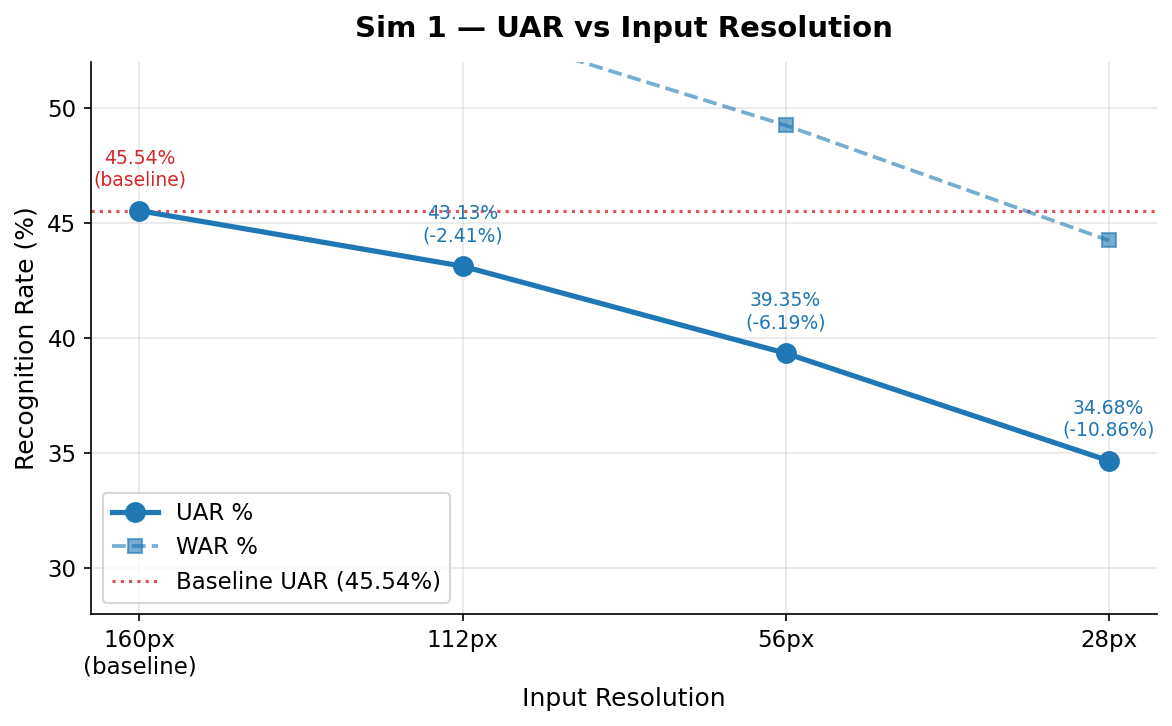

Plot 1 saved ✅


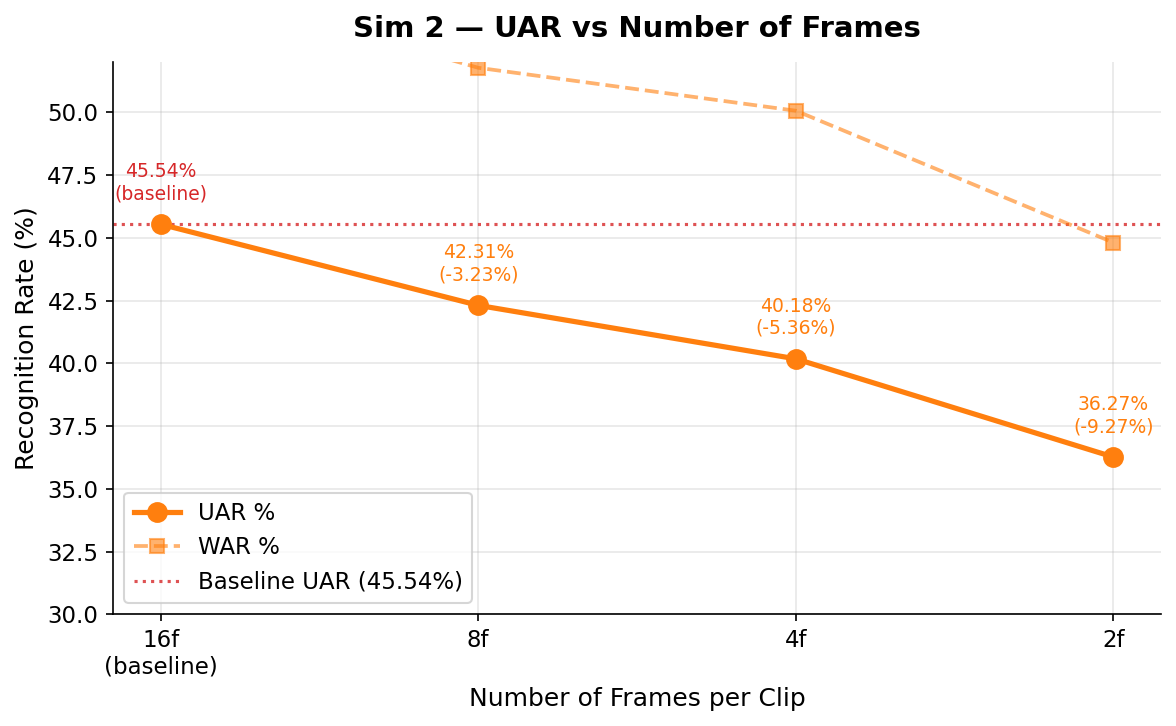

Plot 2 saved ✅


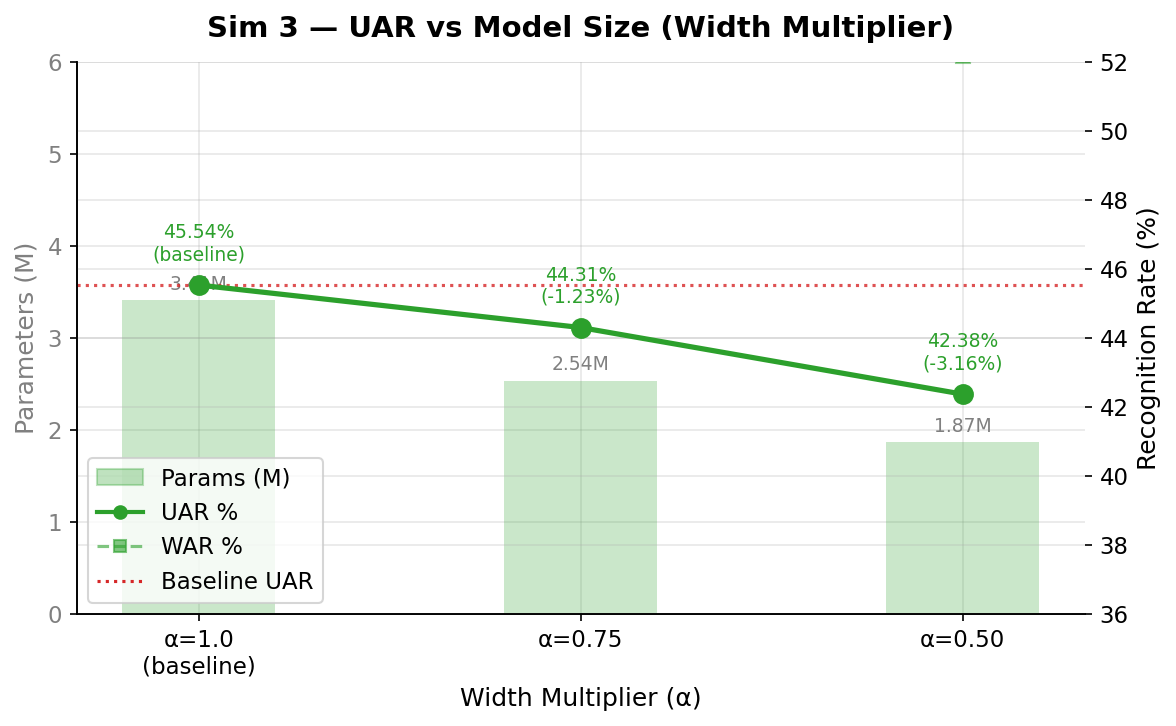

Plot 3 saved ✅


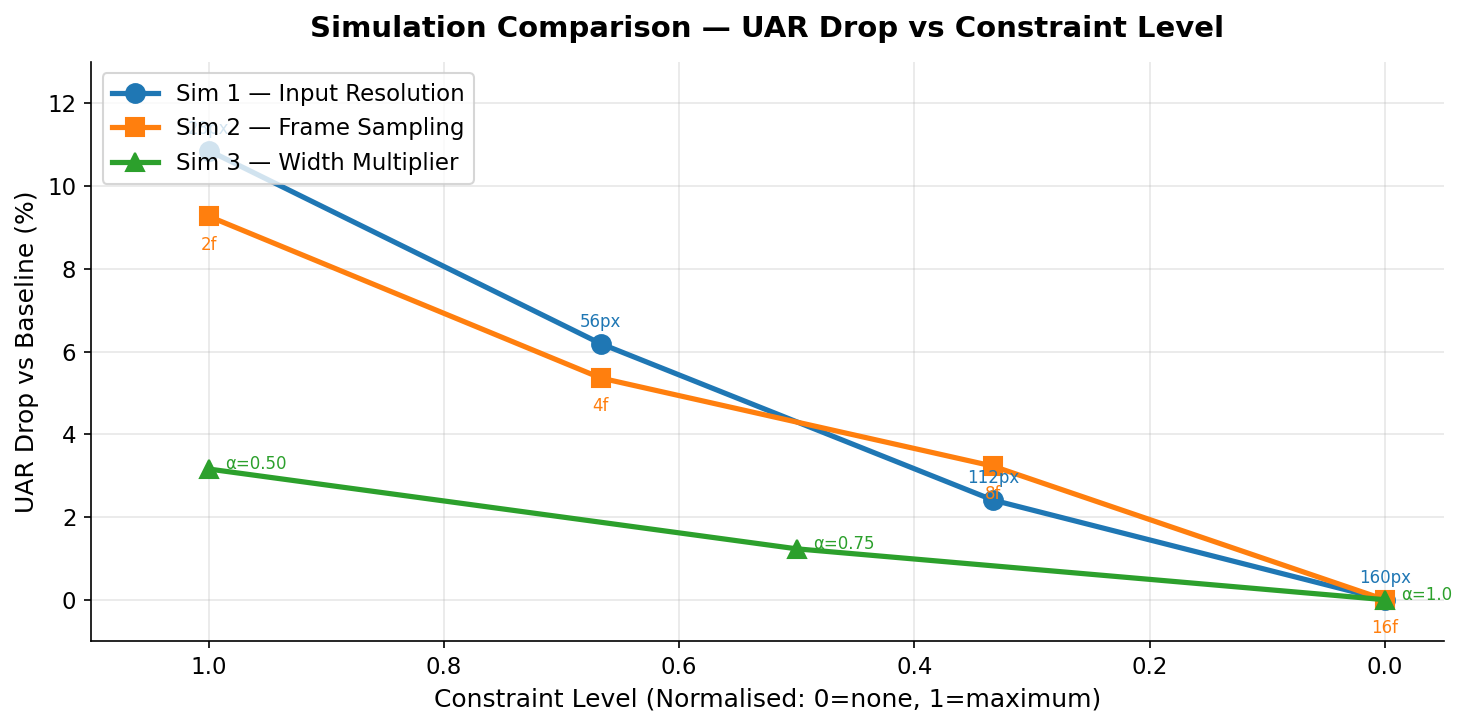

Plot 4 saved ✅


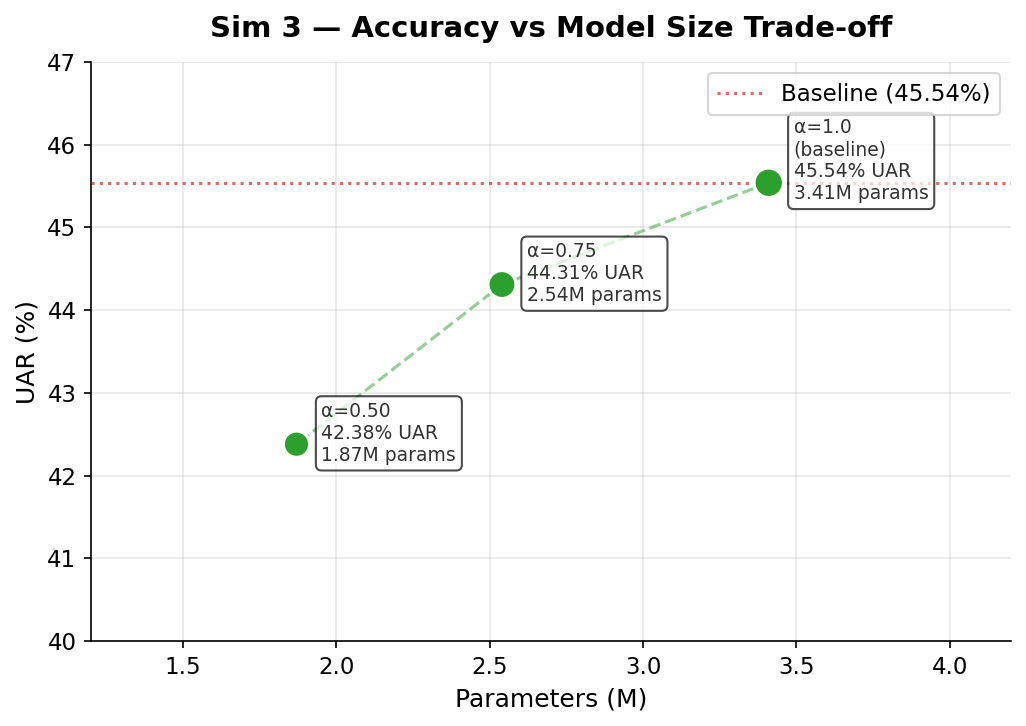

Plot 5 saved ✅

All 5 plots saved to /kaggle/working/sim_plots
Files:
  sim1_resolution.png
  sim2_frames.png
  sim3_tradeoff.png
  sim3_width.png
  sim_combined_drop.png


In [16]:
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import numpy as np
import os

SAVE_DIR = '/kaggle/working/sim_plots'
os.makedirs(SAVE_DIR, exist_ok=True)

# ── Color scheme ──────────────────────────────────────────────
C1 = '#1F77B4'   # blue  — Sim 1
C2 = '#FF7F0E'   # orange — Sim 2
C3 = '#2CA02C'   # green — Sim 3
BASELINE_COLOR = '#D62728'  # red — baseline

plt.rcParams.update({
    'font.family': 'DejaVu Sans',
    'font.size': 12,
    'axes.titlesize': 14,
    'axes.labelsize': 12,
    'xtick.labelsize': 11,
    'ytick.labelsize': 11,
    'legend.fontsize': 11,
    'figure.dpi': 150,
    'axes.grid': True,
    'grid.alpha': 0.3,
    'axes.spines.top': False,
    'axes.spines.right': False,
})

# ══════════════════════════════════════════════════════════════
# DATA
# ══════════════════════════════════════════════════════════════
sim1_labels = ['160px\n(baseline)', '112px', '56px', '28px']
sim1_uar    = [45.54, 43.13, 39.35, 34.68]
sim1_war    = [55.40, 53.61, 49.25, 44.25]
sim1_x      = [160, 112, 56, 28]

sim2_labels = ['16f\n(baseline)', '8f', '4f', '2f']
sim2_uar    = [45.54, 42.31, 40.18, 36.27]
sim2_war    = [55.40, 51.77, 50.06, 44.81]
sim2_x      = [16, 8, 4, 2]

sim3_labels = ['α=1.0\n(baseline)', 'α=0.75', 'α=0.50']
sim3_uar    = [45.54, 44.31, 42.38]
sim3_war    = [55.40, 54.34, 52.16]
sim3_params = [3.41, 2.54, 1.87]

baseline_uar = 45.54

# ══════════════════════════════════════════════════════════════
# PLOT 1 — Sim 1: UAR vs Resolution
# ══════════════════════════════════════════════════════════════
fig, ax = plt.subplots(figsize=(8, 5))
ax.plot(sim1_labels, sim1_uar, 'o-', color=C1, linewidth=2.5,
        markersize=9, label='UAR %', zorder=3)
ax.plot(sim1_labels, sim1_war, 's--', color=C1, linewidth=1.8,
        markersize=7, alpha=0.6, label='WAR %', zorder=3)
ax.axhline(baseline_uar, color=BASELINE_COLOR, linestyle=':', linewidth=1.5,
           label=f'Baseline UAR ({baseline_uar}%)', alpha=0.8)

for i, (y, label) in enumerate(zip(sim1_uar, sim1_labels)):
    drop = baseline_uar - y
    txt = 'baseline' if i == 0 else f'-{drop:.2f}%'
    ax.annotate(f'{y:.2f}%\n({txt})',
                xy=(i, y), xytext=(0, 12),
                textcoords='offset points',
                ha='center', fontsize=9,
                color=C1 if i > 0 else BASELINE_COLOR)

ax.set_title('Sim 1 — UAR vs Input Resolution', fontweight='bold', pad=12)
ax.set_xlabel('Input Resolution')
ax.set_ylabel('Recognition Rate (%)')
ax.set_ylim(28, 52)
ax.legend(loc='lower left')
plt.tight_layout()
plt.savefig(f'{SAVE_DIR}/sim1_resolution.png', bbox_inches='tight')
plt.show()
print("Plot 1 saved ✅")

# ══════════════════════════════════════════════════════════════
# PLOT 2 — Sim 2: UAR vs Frames
# ══════════════════════════════════════════════════════════════
fig, ax = plt.subplots(figsize=(8, 5))
ax.plot(sim2_labels, sim2_uar, 'o-', color=C2, linewidth=2.5,
        markersize=9, label='UAR %', zorder=3)
ax.plot(sim2_labels, sim2_war, 's--', color=C2, linewidth=1.8,
        markersize=7, alpha=0.6, label='WAR %', zorder=3)
ax.axhline(baseline_uar, color=BASELINE_COLOR, linestyle=':', linewidth=1.5,
           label=f'Baseline UAR ({baseline_uar}%)', alpha=0.8)

for i, (y) in enumerate(sim2_uar):
    drop = baseline_uar - y
    txt = 'baseline' if i == 0 else f'-{drop:.2f}%'
    ax.annotate(f'{y:.2f}%\n({txt})',
                xy=(i, y), xytext=(0, 12),
                textcoords='offset points',
                ha='center', fontsize=9,
                color=C2 if i > 0 else BASELINE_COLOR)

ax.set_title('Sim 2 — UAR vs Number of Frames', fontweight='bold', pad=12)
ax.set_xlabel('Number of Frames per Clip')
ax.set_ylabel('Recognition Rate (%)')
ax.set_ylim(30, 52)
ax.legend(loc='lower left')
plt.tight_layout()
plt.savefig(f'{SAVE_DIR}/sim2_frames.png', bbox_inches='tight')
plt.show()
print("Plot 2 saved ✅")

# ══════════════════════════════════════════════════════════════
# PLOT 3 — Sim 3: UAR vs Width Multiplier
# ══════════════════════════════════════════════════════════════
fig, ax1 = plt.subplots(figsize=(8, 5))
ax2 = ax1.twinx()

bars = ax1.bar(sim3_labels, sim3_params, color=C3, alpha=0.25,
               width=0.4, label='Params (M)', zorder=2)
line1, = ax1.plot([], [], color=C3, alpha=0.4,
                  linewidth=0, marker='s', label='Params (M)')
line2, = ax2.plot(sim3_labels, sim3_uar, 'o-', color=C3,
                  linewidth=2.5, markersize=9, label='UAR %', zorder=3)
ax2.plot(sim3_labels, sim3_war, 's--', color=C3, linewidth=1.8,
         markersize=7, alpha=0.5, label='WAR %', zorder=3)
ax2.axhline(baseline_uar, color=BASELINE_COLOR, linestyle=':',
            linewidth=1.5, alpha=0.8)

for i, (y, p) in enumerate(zip(sim3_uar, sim3_params)):
    drop = baseline_uar - y
    txt = 'baseline' if i == 0 else f'-{drop:.2f}%'
    ax2.annotate(f'{y:.2f}%\n({txt})',
                 xy=(i, y), xytext=(0, 12),
                 textcoords='offset points',
                 ha='center', fontsize=9, color=C3)
    ax1.annotate(f'{p}M', xy=(i, p), xytext=(0, 5),
                 textcoords='offset points',
                 ha='center', fontsize=9, color='grey')

ax1.set_xlabel('Width Multiplier (α)')
ax1.set_ylabel('Parameters (M)', color='grey')
ax2.set_ylabel('Recognition Rate (%)')
ax1.set_ylim(0, 6)
ax2.set_ylim(36, 52)
ax1.tick_params(axis='y', labelcolor='grey')
ax2.set_title('Sim 3 — UAR vs Model Size (Width Multiplier)',
              fontweight='bold', pad=12)

lines = [mpatches.Patch(color=C3, alpha=0.3, label='Params (M)'),
         plt.Line2D([0],[0], color=C3, marker='o', linewidth=2, label='UAR %'),
         plt.Line2D([0],[0], color=C3, marker='s', linestyle='--',
                    linewidth=1.5, alpha=0.6, label='WAR %'),
         plt.Line2D([0],[0], color=BASELINE_COLOR, linestyle=':',
                    linewidth=1.5, label=f'Baseline UAR')]
ax2.legend(handles=lines, loc='lower left')
plt.tight_layout()
plt.savefig(f'{SAVE_DIR}/sim3_width.png', bbox_inches='tight')
plt.show()
print("Plot 3 saved ✅")

# ══════════════════════════════════════════════════════════════
# PLOT 4 — Combined: Normalised UAR Drop All Sims
# ══════════════════════════════════════════════════════════════
fig, ax = plt.subplots(figsize=(10, 5))

# Normalised x axis 0-1 for each sim, UAR drop
s1_drop = [0, 2.41, 6.19, 10.86]
s2_drop = [0, 3.23, 5.36, 9.27]
s3_drop = [0, 1.23, 3.16]

s1_pos = np.linspace(0, 1, 4)
s2_pos = np.linspace(0, 1, 4)
s3_pos = np.linspace(0, 1, 3)

ax.plot(s1_pos, s1_drop, 'o-', color=C1, linewidth=2.5,
        markersize=9, label='Sim 1 — Input Resolution')
ax.plot(s2_pos, s2_drop, 's-', color=C2, linewidth=2.5,
        markersize=9, label='Sim 2 — Frame Sampling')
ax.plot(s3_pos, s3_drop, '^-', color=C3, linewidth=2.5,
        markersize=9, label='Sim 3 — Width Multiplier')

# Labels for key points
for x, y, lbl in zip(s1_pos, s1_drop, ['160px','112px','56px','28px']):
    ax.annotate(lbl, (x, y), textcoords='offset points',
                xytext=(0, 8), ha='center', fontsize=8, color=C1)
for x, y, lbl in zip(s2_pos, s2_drop, ['16f','8f','4f','2f']):
    ax.annotate(lbl, (x, y), textcoords='offset points',
                xytext=(0, -16), ha='center', fontsize=8, color=C2)
for x, y, lbl in zip(s3_pos, s3_drop, ['α=1.0','α=0.75','α=0.50']):
    ax.annotate(lbl, (x, y), textcoords='offset points',
                xytext=(8, 0), ha='left', fontsize=8, color=C3)

ax.set_title('Simulation Comparison — UAR Drop vs Constraint Level',
             fontweight='bold', pad=12)
ax.set_xlabel('Constraint Level (Normalised: 0=none, 1=maximum)')
ax.set_ylabel('UAR Drop vs Baseline (%)')
ax.set_xlim(-0.05, 1.1)
ax.set_ylim(-1, 13)
ax.legend(loc='upper left')
ax.invert_xaxis()
plt.tight_layout()
plt.savefig(f'{SAVE_DIR}/sim_combined_drop.png', bbox_inches='tight')
plt.show()
print("Plot 4 saved ✅")

# ══════════════════════════════════════════════════════════════
# PLOT 5 — Accuracy-Efficiency Trade-off (Sim 3)
# ══════════════════════════════════════════════════════════════
fig, ax = plt.subplots(figsize=(7, 5))

scatter = ax.scatter(sim3_params, sim3_uar,
                     s=[200, 180, 160], c=[C3]*3,
                     zorder=3, edgecolors='white', linewidth=1.5)
ax.plot(sim3_params, sim3_uar, '--', color=C3,
        linewidth=1.5, alpha=0.5, zorder=2)

for p, u, lbl in zip(sim3_params, sim3_uar,
                     ['α=1.0\n(baseline)', 'α=0.75', 'α=0.50']):
    ax.annotate(f'{lbl}\n{u:.2f}% UAR\n{p}M params',
                xy=(p, u), xytext=(12, -8),
                textcoords='offset points',
                fontsize=9, color='#333333',
                bbox=dict(boxstyle='round,pad=0.3',
                          facecolor='white', alpha=0.7))

ax.axhline(baseline_uar, color=BASELINE_COLOR, linestyle=':',
           linewidth=1.5, alpha=0.7, label=f'Baseline ({baseline_uar}%)')
ax.set_title('Sim 3 — Accuracy vs Model Size Trade-off',
             fontweight='bold', pad=12)
ax.set_xlabel('Parameters (M)')
ax.set_ylabel('UAR (%)')
ax.set_xlim(1.2, 4.2)
ax.set_ylim(40, 47)
ax.legend()
plt.tight_layout()
plt.savefig(f'{SAVE_DIR}/sim3_tradeoff.png', bbox_inches='tight')
plt.show()
print("Plot 5 saved ✅")

print(f"\nAll 5 plots saved to {SAVE_DIR}")
print("Files:")
for f in sorted(os.listdir(SAVE_DIR)):
    print(f"  {f}")

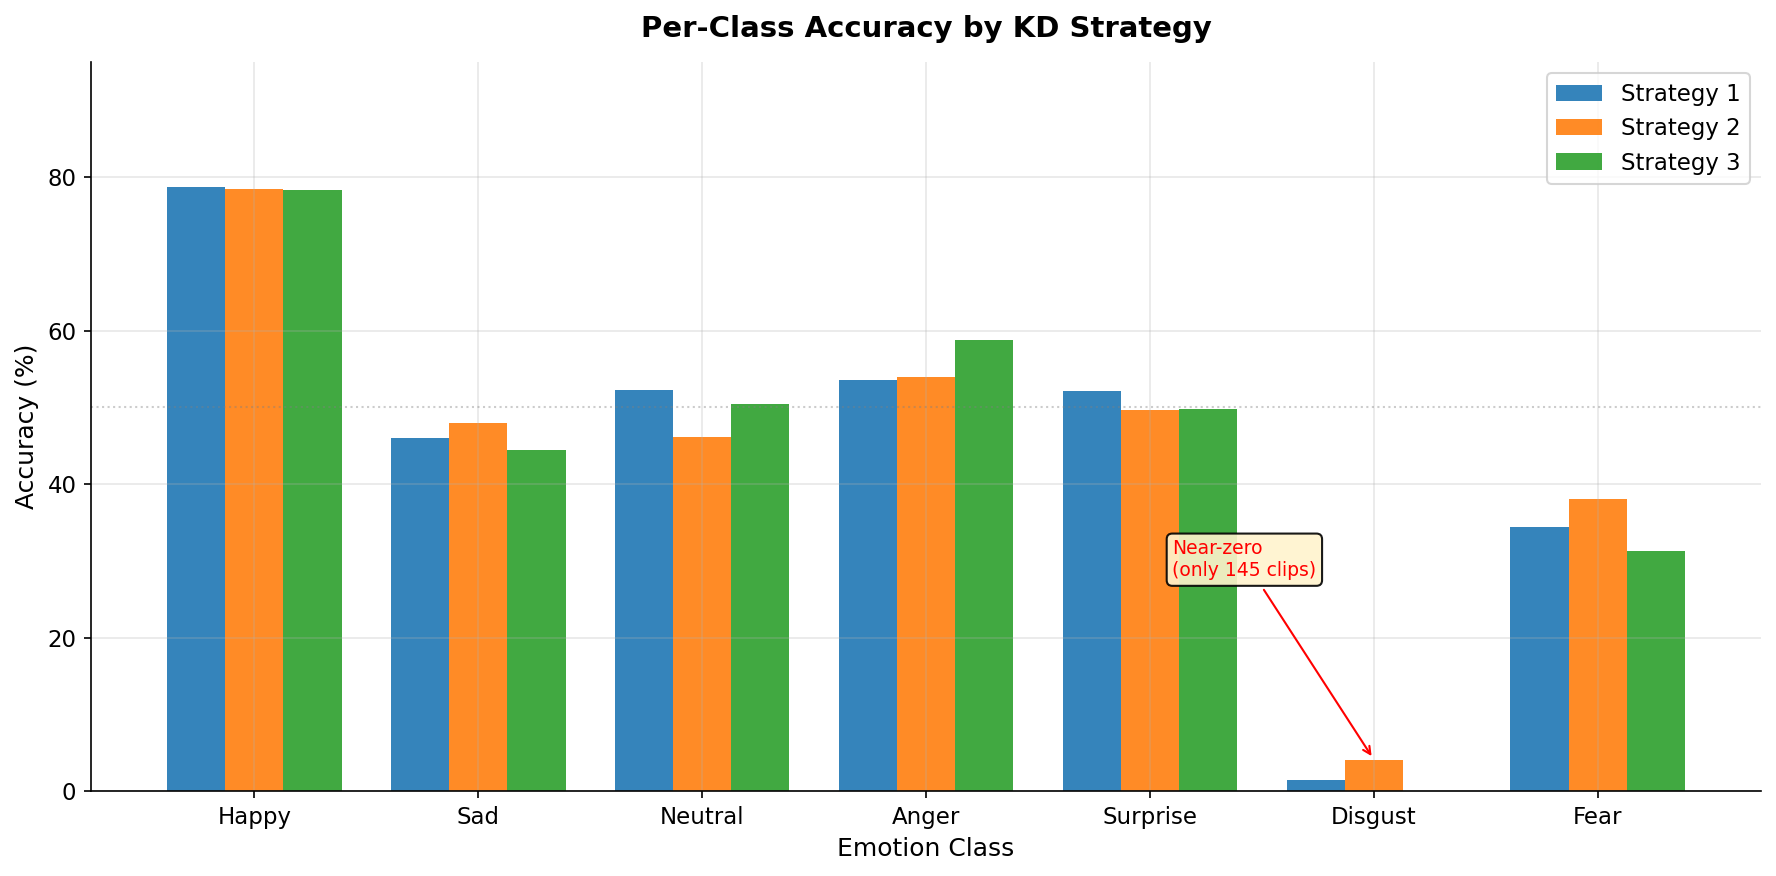

Plot 1 saved ✅


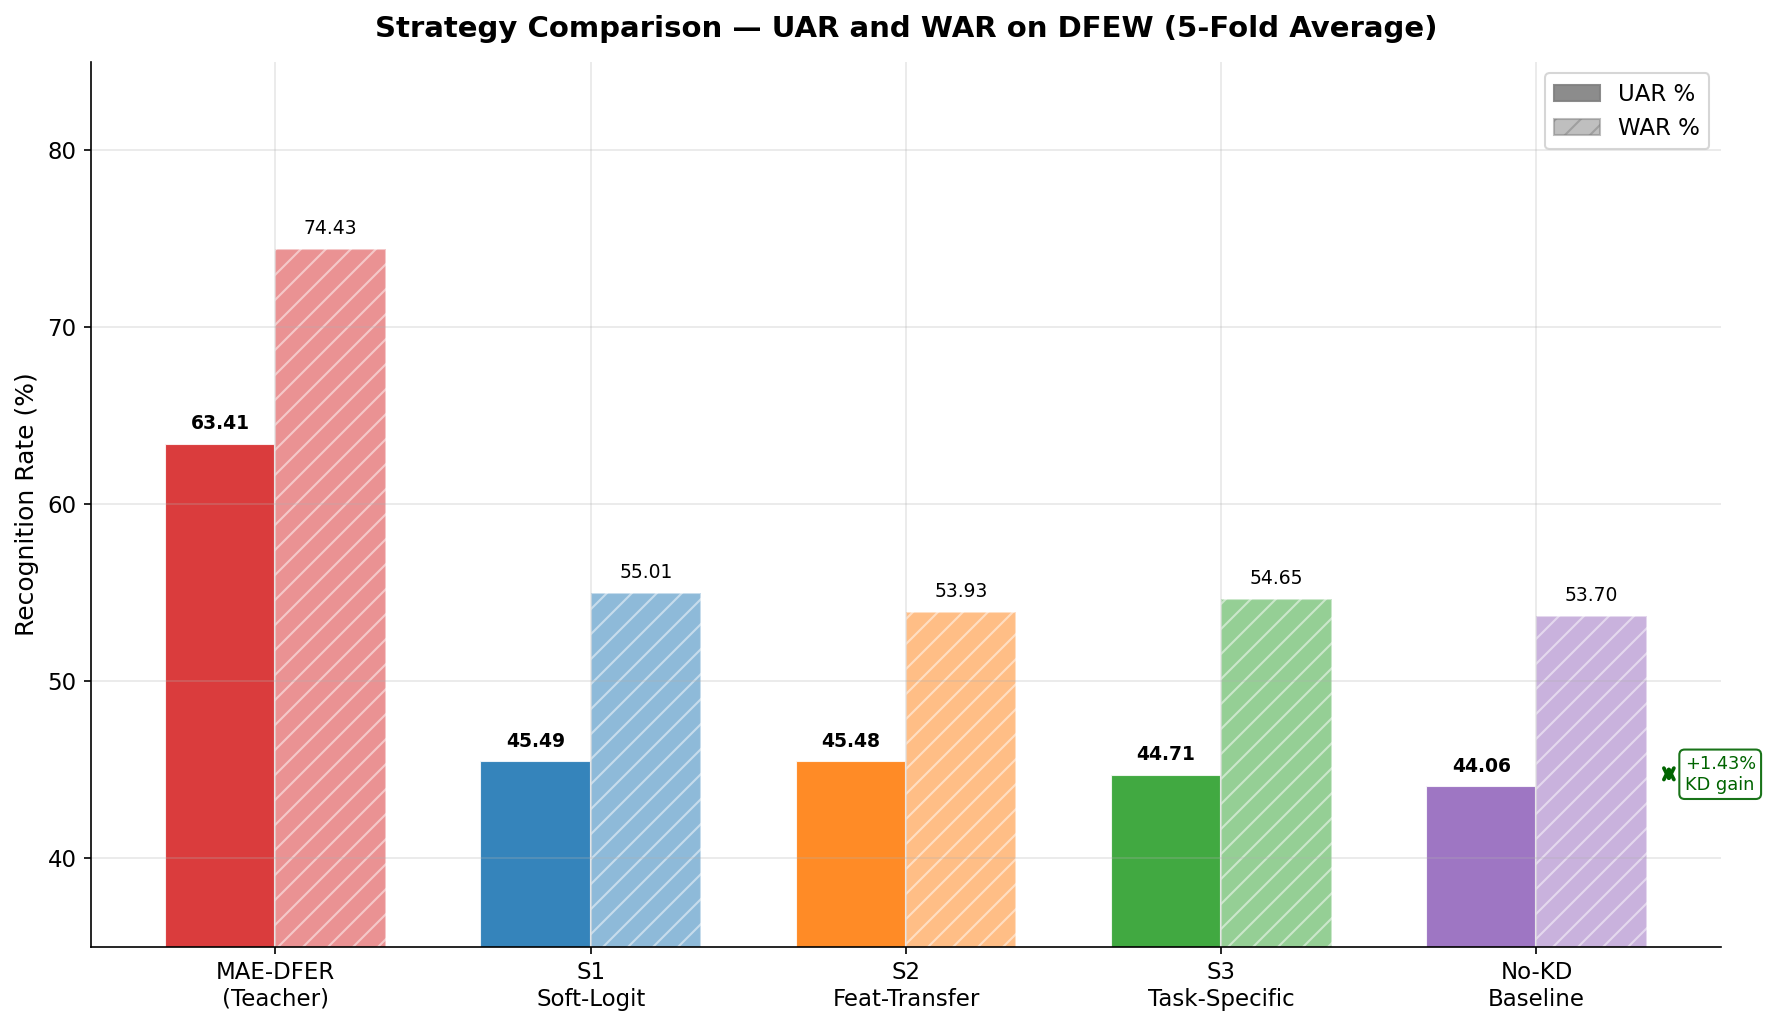

Plot 2 saved ✅


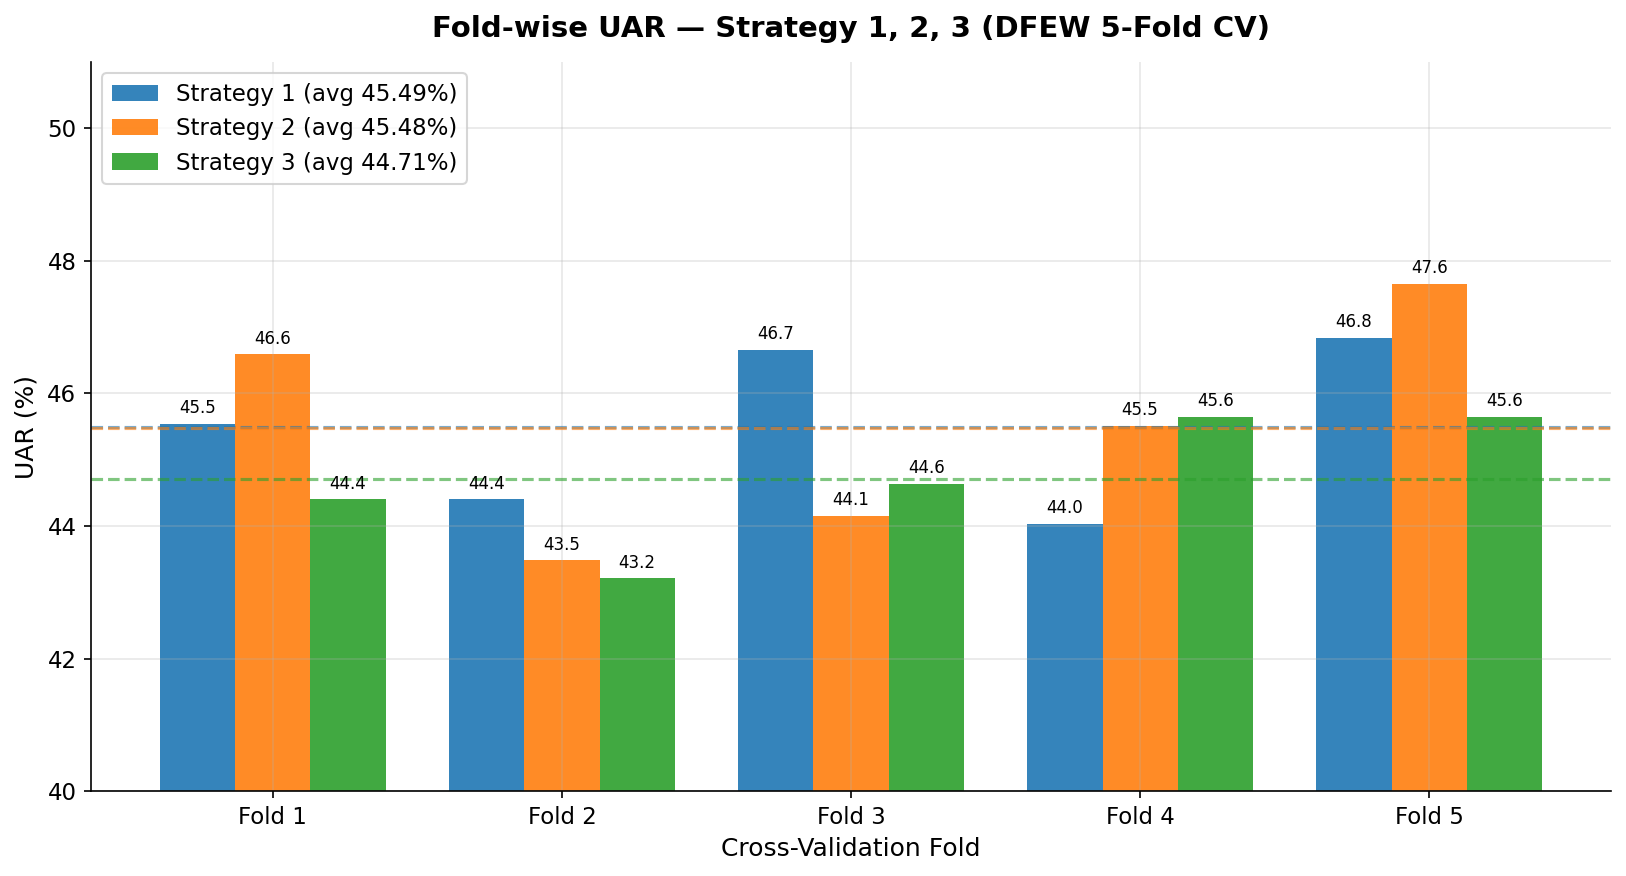

Plot 3 saved ✅


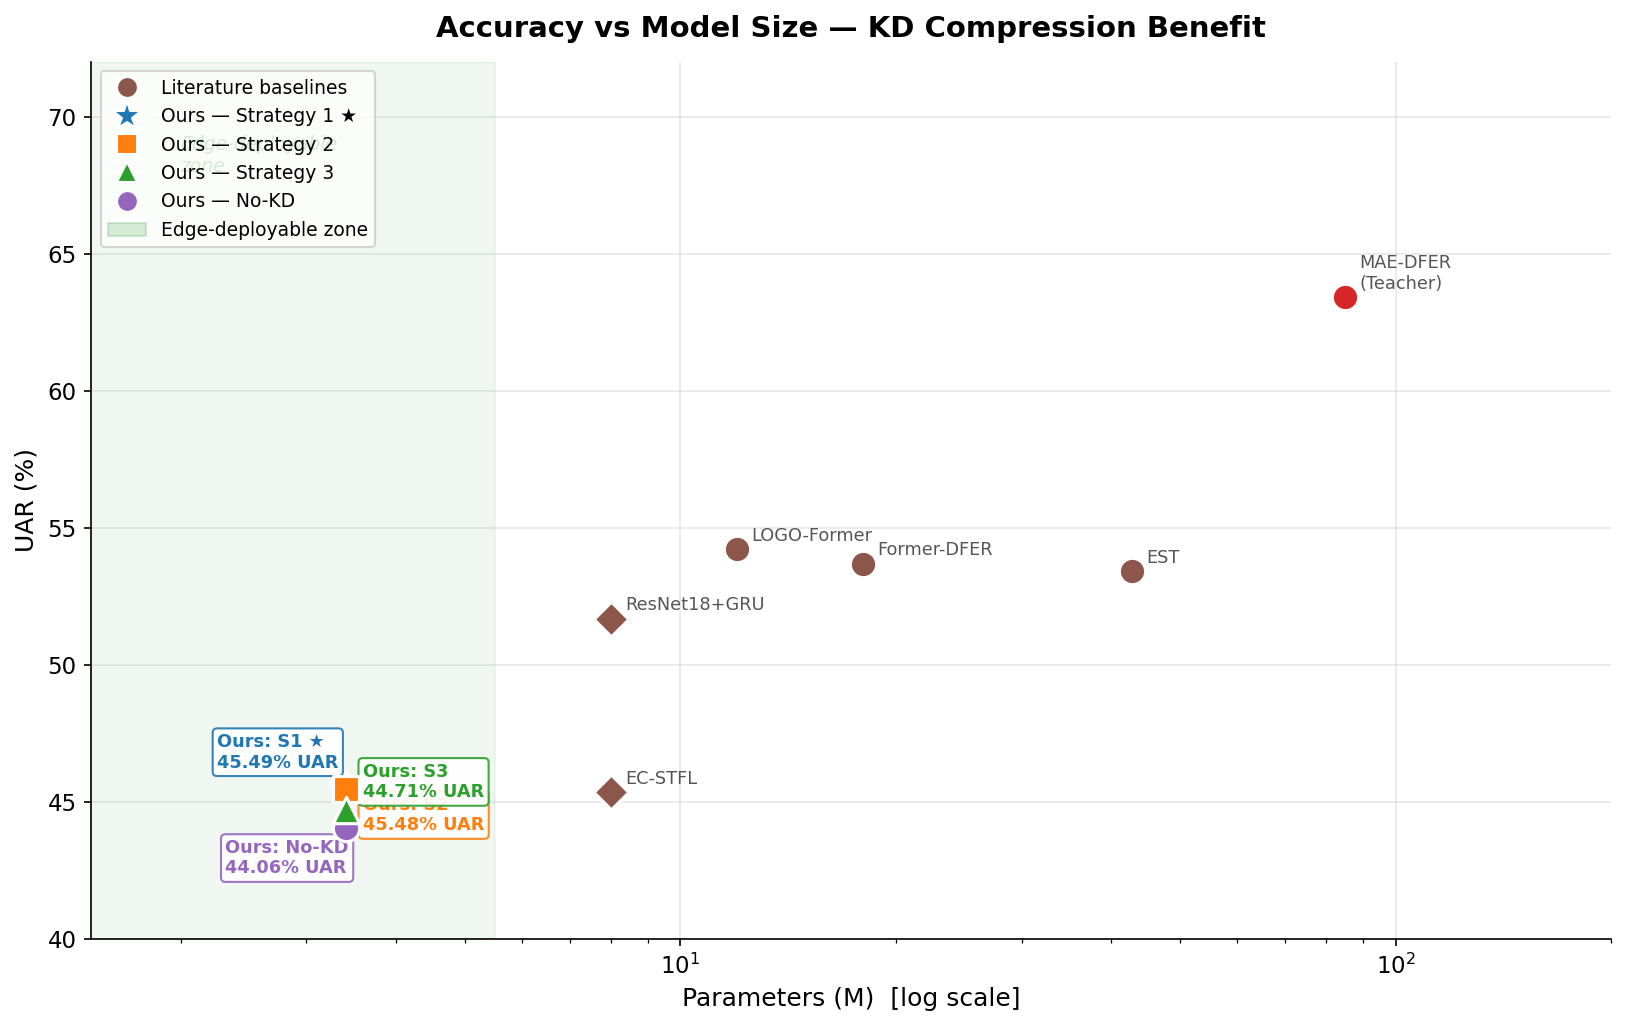

Plot 4 saved ✅

All 4 plots saved to /kaggle/working/main_plots
  plot1_perclass.png
  plot2_strategy_comparison.png
  plot3_foldwise.png
  plot4_compression_scatter.png


In [20]:
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import numpy as np
import os

SAVE_DIR = '/kaggle/working/main_plots'
os.makedirs(SAVE_DIR, exist_ok=True)

plt.rcParams.update({
    'font.family': 'DejaVu Sans',
    'font.size': 12,
    'axes.titlesize': 14,
    'axes.labelsize': 12,
    'xtick.labelsize': 11,
    'ytick.labelsize': 11,
    'legend.fontsize': 11,
    'figure.dpi': 150,
    'axes.grid': True,
    'grid.alpha': 0.3,
    'axes.spines.top': False,
    'axes.spines.right': False,
})

C1 = '#1F77B4'
C2 = '#FF7F0E'
C3 = '#2CA02C'
CNOKD  = '#9467BD'
CTEACH = '#D62728'

# ══════════════════════════════════════════════════════════════
# PLOT 1 — Per-Class Accuracy (all 3 strategies)
# ══════════════════════════════════════════════════════════════
emotions = ['Happy', 'Sad', 'Neutral', 'Anger', 'Surprise', 'Disgust', 'Fear']
s1_class = [78.7, 46.0, 52.3, 53.6, 52.1,  1.4, 34.4]
s2_class = [78.4, 48.0, 46.2, 53.9, 49.6,  4.1, 38.1]
s3_class = [78.3, 44.4, 50.4, 58.8, 49.8,  0.0, 31.3]

x = np.arange(len(emotions))
w = 0.26

fig, ax = plt.subplots(figsize=(12, 6))
b1 = ax.bar(x - w, s1_class, w, label='Strategy 1', color=C1, alpha=0.9)
b2 = ax.bar(x,     s2_class, w, label='Strategy 2', color=C2, alpha=0.9)
b3 = ax.bar(x + w, s3_class, w, label='Strategy 3', color=C3, alpha=0.9)

ax.annotate('Near-zero\n(only 145 clips)',
            xy=(5, 4.1), xytext=(4.1, 28),
            arrowprops=dict(arrowstyle='->', color='red'),
            fontsize=9, color='red',
            bbox=dict(boxstyle='round,pad=0.3',
                      facecolor='#fff3cd', alpha=0.9))

ax.set_title('Per-Class Accuracy by KD Strategy', fontweight='bold', pad=12)
ax.set_xlabel('Emotion Class')
ax.set_ylabel('Accuracy (%)')
ax.set_xticks(x)
ax.set_xticklabels(emotions)
ax.set_ylim(0, 95)
ax.legend(loc='upper right')
ax.axhline(50, color='grey', linestyle=':', alpha=0.4, linewidth=1)
plt.tight_layout()
plt.savefig(f'{SAVE_DIR}/plot1_perclass.png', bbox_inches='tight')
plt.show()
print("Plot 1 saved ✅")

# ══════════════════════════════════════════════════════════════
# PLOT 2 — Strategy Comparison (UAR + WAR) — FIXED
# ══════════════════════════════════════════════════════════════
models   = ['MAE-DFER\n(Teacher)', 'S1\nSoft-Logit', 'S2\nFeat-Transfer',
            'S3\nTask-Specific', 'No-KD\nBaseline']
uar_vals = [63.41, 45.49, 45.48, 44.71, 44.06]
war_vals = [74.43, 55.01, 53.93, 54.65, 53.70]
colors   = [CTEACH, C1, C2, C3, CNOKD]

x = np.arange(len(models))
w = 0.35

fig, ax = plt.subplots(figsize=(12, 7))
bars_uar = ax.bar(x - w/2, uar_vals, w, label='UAR %',
                  color=colors, alpha=0.9, edgecolor='white')
bars_war = ax.bar(x + w/2, war_vals, w, label='WAR %',
                  color=colors, alpha=0.5, edgecolor='white', hatch='//')

for bar, val in zip(bars_uar, uar_vals):
    ax.text(bar.get_x() + bar.get_width()/2,
            bar.get_height() + 0.6,
            f'{val:.2f}',
            ha='center', va='bottom',
            fontsize=9, fontweight='bold', color='black')

for bar, val in zip(bars_war, war_vals):
    ax.text(bar.get_x() + bar.get_width()/2,
            bar.get_height() + 0.6,
            f'{val:.2f}',
            ha='center', va='bottom',
            fontsize=9, color='black')

# KD gain bracket — placed outside bars on right
ax.annotate('', xy=(4.42, 45.49), xytext=(4.42, 44.06),
            arrowprops=dict(arrowstyle='<->', color='darkgreen', lw=1.8))
ax.text(4.47, 44.75, '+1.43%\nKD gain',
        fontsize=8.5, color='darkgreen', va='center',
        bbox=dict(boxstyle='round,pad=0.3',
                  facecolor='white', edgecolor='darkgreen', alpha=0.9))

ax.set_title('Strategy Comparison — UAR and WAR on DFEW (5-Fold Average)',
             fontweight='bold', pad=12)
ax.set_ylabel('Recognition Rate (%)')
ax.set_xticks(x)
ax.set_xticklabels(models)
ax.set_ylim(35, 85)

uar_patch = mpatches.Patch(color='grey', alpha=0.9, label='UAR %')
war_patch = mpatches.Patch(color='grey', alpha=0.5, hatch='//', label='WAR %')
ax.legend(handles=[uar_patch, war_patch], loc='upper right')
plt.tight_layout()
plt.savefig(f'{SAVE_DIR}/plot2_strategy_comparison.png', bbox_inches='tight')
plt.show()
print("Plot 2 saved ✅")

# ══════════════════════════════════════════════════════════════
# PLOT 3 — Fold-wise UAR (5 folds × 3 strategies)
# ══════════════════════════════════════════════════════════════
folds    = ['Fold 1', 'Fold 2', 'Fold 3', 'Fold 4', 'Fold 5']
s1_folds = [45.54, 44.40, 46.66, 44.03, 46.84]
s2_folds = [46.59, 43.48, 44.15, 45.51, 47.65]
s3_folds = [44.40, 43.21, 44.64, 45.65, 45.65]

x = np.arange(5)
w = 0.26

fig, ax = plt.subplots(figsize=(11, 6))
b1 = ax.bar(x - w, s1_folds, w, label='Strategy 1 (avg 45.49%)', color=C1, alpha=0.9)
b2 = ax.bar(x,     s2_folds, w, label='Strategy 2 (avg 45.48%)', color=C2, alpha=0.9)
b3 = ax.bar(x + w, s3_folds, w, label='Strategy 3 (avg 44.71%)', color=C3, alpha=0.9)

ax.axhline(45.49, color=C1, linestyle='--', linewidth=1.5, alpha=0.6)
ax.axhline(45.48, color=C2, linestyle='--', linewidth=1.5, alpha=0.6)
ax.axhline(44.71, color=C3, linestyle='--', linewidth=1.5, alpha=0.6)

for bars in [b1, b2, b3]:
    for bar in bars:
        ax.text(bar.get_x() + bar.get_width()/2,
                bar.get_height() + 0.1,
                f'{bar.get_height():.1f}',
                ha='center', va='bottom', fontsize=8)

ax.set_title('Fold-wise UAR — Strategy 1, 2, 3 (DFEW 5-Fold CV)',
             fontweight='bold', pad=12)
ax.set_xlabel('Cross-Validation Fold')
ax.set_ylabel('UAR (%)')
ax.set_xticks(x)
ax.set_xticklabels(folds)
ax.set_ylim(40, 51)
ax.legend(loc='upper left')
plt.tight_layout()
plt.savefig(f'{SAVE_DIR}/plot3_foldwise.png', bbox_inches='tight')
plt.show()
print("Plot 3 saved ✅")

# ══════════════════════════════════════════════════════════════
# PLOT 4 — Compression vs Accuracy Scatter — FIXED
# ══════════════════════════════════════════════════════════════
fig, ax = plt.subplots(figsize=(11, 7))

# Literature baselines — known params
lit_known = [
    (84.9,  63.41, 'MAE-DFER\n(Teacher)', CTEACH,    'o'),
    (42.78, 53.43, 'EST',                 '#8C564B',  'o'),
    (18,    53.69, 'Former-DFER',         '#8C564B',  'o'),
    (12,    54.21, 'LOGO-Former',         '#8C564B',  'o'),
]
# Literature baselines — approx params
lit_approx = [
    (8, 51.68, 'ResNet18+GRU', '#8C564B', 'D'),
    (8, 45.35, 'EC-STFL',     '#8C564B', 'D'),
]

for p, u, lbl, c, mk in lit_known:
    ax.scatter(p, u, s=160, color=c, zorder=3,
               edgecolors='white', linewidth=1.5, marker=mk)
    ax.annotate(lbl, (p, u), textcoords='offset points',
                xytext=(7, 4), fontsize=8.5, color='#555')

for p, u, lbl, c, mk in lit_approx:
    ax.scatter(p, u, s=140, color=c, zorder=3,
               edgecolors='white', linewidth=1.5, marker=mk)
    ax.annotate(lbl, (p, u), textcoords='offset points',
                xytext=(7, 4), fontsize=8.5, color='#555')

# Our models — individual offsets to prevent overlap
our_models = [
    # params, uar, label, color, marker, size, xytext
    (3.41, 44.06, 'No-KD', CNOKD, 'o', 160, (-58, -22)),
    (3.41, 45.49, 'S1 ★',  C1,    '*', 300, (-62,  10)),
    (3.41, 45.48, 'S2',    C2,    's', 160, (  8, -20)),
    (3.41, 44.71, 'S3',    C3,    '^', 160, (  8,   6)),
]

for p, u, lbl, c, mk, sz, offset in our_models:
    ax.scatter(p, u, s=sz, color=c, zorder=5,
               edgecolors='white', linewidth=1.5, marker=mk)
    ax.annotate(f'Ours: {lbl}\n{u:.2f}% UAR',
                xy=(p, u),
                xytext=offset,
                textcoords='offset points',
                fontsize=8.5, color=c, fontweight='bold',
                bbox=dict(boxstyle='round,pad=0.25',
                          facecolor='white',
                          edgecolor=c,
                          alpha=0.9))

ax.axvspan(1.5, 5.5, alpha=0.06, color='green')
ax.text(2.0, 68.0, 'Edge-deployable\nzone',
        fontsize=9, color='green', alpha=0.8, style='italic')

ax.set_title('Accuracy vs Model Size — KD Compression Benefit',
             fontweight='bold', pad=12)
ax.set_xlabel('Parameters (M)  [log scale]')
ax.set_ylabel('UAR (%)')
ax.set_xscale('log')
ax.set_xlim(1.5, 200)
ax.set_ylim(40, 72)

leg_elements = [
    plt.Line2D([0],[0], marker='o', color='w',
               markerfacecolor='#8C564B', markersize=10,
               label='Literature baselines'),
    plt.Line2D([0],[0], marker='*', color='w',
               markerfacecolor=C1, markersize=14,
               label='Ours — Strategy 1 ★'),
    plt.Line2D([0],[0], marker='s', color='w',
               markerfacecolor=C2, markersize=10,
               label='Ours — Strategy 2'),
    plt.Line2D([0],[0], marker='^', color='w',
               markerfacecolor=C3, markersize=10,
               label='Ours — Strategy 3'),
    plt.Line2D([0],[0], marker='o', color='w',
               markerfacecolor=CNOKD, markersize=10,
               label='Ours — No-KD'),
    mpatches.Patch(color='green', alpha=0.15,
                   label='Edge-deployable zone'),
]
ax.legend(handles=leg_elements, loc='upper left', fontsize=9)
plt.tight_layout()
plt.savefig(f'{SAVE_DIR}/plot4_compression_scatter.png', bbox_inches='tight')
plt.show()
print("Plot 4 saved ✅")

print(f"\nAll 4 plots saved to {SAVE_DIR}")
for f in sorted(os.listdir(SAVE_DIR)):
    if f.endswith('.png'):
        print(f"  {f}")

In [22]:
# For Confusion Matrix
import os
import torch
import numpy as np
import matplotlib
matplotlib.use('Agg')
import matplotlib.pyplot as plt
from collections import defaultdict
import shutil
import json
import subprocess

# ── Config ────────────────────────────────────────────────────
CLASS_NAMES  = ['Happy', 'Sad', 'Neutral',
                'Anger', 'Surprise', 'Disgust', 'Fear']
SAVE_DIR     = '/kaggle/working/evaluation'
DATASET_PATH = '/kaggle/input/datasets/faiqhassan98/kd-fer-checkpoints'
UPLOAD_DIR   = '/kaggle/working/eval_upload'
DATASET_ID   = 'faiqhassan98/kd-fer-checkpoints'

os.makedirs(SAVE_DIR,   exist_ok=True)
os.makedirs(UPLOAD_DIR, exist_ok=True)

# ── Find best checkpoint ──────────────────────────────────────
def load_best_checkpoint(strategy, fold):
    fname = f'student_s{strategy}_fold{fold}_best.pth'
    for base in ['/kaggle/working', DATASET_PATH]:
        path = os.path.join(base, fname)
        if os.path.exists(path):
            return path
    return None

# ── Collect predictions across all 5 folds ───────────────────
def evaluate_strategy(strategy):
    all_preds, all_labels = [], []
    print(f"\n{'='*52}")
    print(f"Strategy {strategy} — Evaluating all 5 folds")
    print(f"{'='*52}")

    for fold in range(1, 6):
        path = load_best_checkpoint(strategy, fold)
        if not path:
            print(f"  Fold {fold}: NOT FOUND ❌")
            continue

        ckpt = torch.load(path, map_location=device,
                          weights_only=False)

        student_eval = MobileNetV2GRU(
            num_classes=7, width_mult=1.0,
            gru_hidden=256, num_frames=16, dropout=0.3
        ).to(device)
        student_eval.load_state_dict(ckpt['model'])
        student_eval.eval()

        _, test_loader_eval = build_dataloaders(
            fold=fold, num_frames=16,
            input_size=160, batch_size=8
        )

        fold_preds, fold_labels = [], []
        with torch.no_grad():
            for videos, labels in test_loader_eval:
                videos = videos.to(device)
                preds  = student_eval(videos).argmax(1).cpu()
                fold_preds.extend(preds.tolist())
                fold_labels.extend(labels.tolist())

        # Per-fold UAR
        cc = defaultdict(int)
        ct = defaultdict(int)
        for p, l in zip(fold_preds, fold_labels):
            ct[l] += 1
            cc[l] += int(p == l)
        fold_uar = sum(cc[c]/ct[c] for c in ct) / 7 * 100
        print(f"  Fold {fold}: UAR {fold_uar:.2f}%  [{os.path.basename(path)}]")

        all_preds.extend(fold_preds)
        all_labels.extend(fold_labels)

    return all_preds, all_labels


# ── Per-class accuracy ────────────────────────────────────────
def per_class_accuracy(preds, labels, strategy):
    cc = defaultdict(int)
    ct = defaultdict(int)
    for p, l in zip(preds, labels):
        ct[l] += 1
        cc[l] += int(p == l)

    accs = []
    print(f"\nPer-Class Accuracy — Strategy {strategy}")
    print("-" * 44)
    for i, name in enumerate(CLASS_NAMES):
        acc = cc[i] / ct[i] * 100 if ct[i] > 0 else 0.0
        bar = "█" * int(acc / 5)
        print(f"  {name:<10}: {acc:5.1f}%  {bar}")
        accs.append(acc)

    uar = sum(accs) / 7
    war = sum(p==l for p,l in zip(preds,labels)) / len(labels) * 100
    print("-" * 44)
    print(f"  UAR : {uar:.2f}%")
    print(f"  WAR : {war:.2f}%")
    return accs, uar, war


# ── Confusion matrix ──────────────────────────────────────────
def plot_confusion_matrix(preds, labels, strategy, uar, war):
    cm = np.zeros((7, 7), dtype=int)
    for p, l in zip(preds, labels):
        cm[l][p] += 1

    # Print raw numbers — always visible in notebook output
    print(f"\nConfusion Matrix — Strategy {strategy} "
          f"(rows=True label, cols=Predicted)")
    print(f"{'':>12}", end="")
    for n in CLASS_NAMES:
        print(f"{n[:4]:>7}", end="")
    print()
    for i, n in enumerate(CLASS_NAMES):
        print(f"{n:<12}", end="")
        for j in range(7):
            print(f"{cm[i][j]:>7}", end="")
        print()

    # Normalise per row
    cm_norm = cm.astype(float)
    for i in range(7):
        if cm[i].sum() > 0:
            cm_norm[i] = cm[i] / cm[i].sum() * 100

    # Plot
    fig, ax = plt.subplots(figsize=(9, 7))
    im = ax.imshow(cm_norm, interpolation='nearest',
                   cmap='Blues', vmin=0, vmax=100)
    cbar = fig.colorbar(im, ax=ax, fraction=0.046, pad=0.04)
    cbar.set_label('Accuracy (%)', fontsize=11)

    ax.set_xticks(range(7))
    ax.set_yticks(range(7))
    ax.set_xticklabels(CLASS_NAMES, rotation=30,
                       ha='right', fontsize=11)
    ax.set_yticklabels(CLASS_NAMES, fontsize=11)
    ax.set_xlabel('Predicted', fontsize=12, fontweight='bold')
    ax.set_ylabel('True Label', fontsize=12, fontweight='bold')

    s_names = {1:'Soft-Logit Matching',
               2:'Feature Transfer',
               3:'Task-Specific Loss'}
    ax.set_title(
        f'Strategy {strategy} — {s_names[strategy]}\n'
        f'UAR: {uar:.2f}%  |  WAR: {war:.2f}%',
        fontsize=13, fontweight='bold', pad=12
    )

    thresh = 50
    for i in range(7):
        for j in range(7):
            val   = cm_norm[i][j]
            raw   = cm[i][j]
            color = 'white' if val > thresh else 'black'
            ax.text(j, i, f'{val:.1f}%\n({raw})',
                    ha='center', va='center',
                    fontsize=9, color=color)

    plt.tight_layout()
    png_path = f'{SAVE_DIR}/confusion_matrix_s{strategy}.png'
    plt.savefig(png_path, dpi=150, bbox_inches='tight')
    plt.close()
    print(f"PNG saved: {png_path} ✅")
    return png_path


# ── Run all three strategies ──────────────────────────────────
results_summary = {}

for strategy in [1, 2, 3]:
    preds, labels = evaluate_strategy(strategy)
    if not preds:
        print(f"Strategy {strategy}: no predictions found ❌")
        continue
    accs, uar, war = per_class_accuracy(preds, labels, strategy)
    plot_confusion_matrix(preds, labels, strategy, uar, war)
    results_summary[strategy] = {
        'per_class': dict(zip(CLASS_NAMES, accs)),
        'uar': uar,
        'war': war,
    }


# ── Final summary table ───────────────────────────────────────
print("\n" + "="*60)
print("FINAL SUMMARY — Per-Class Accuracy All Strategies")
print("="*60)
print(f"{'Emotion':<12}{'S1 (%)':>10}{'S2 (%)':>10}{'S3 (%)':>10}")
print("-"*60)
for name in CLASS_NAMES:
    print(f"{name:<12}", end="")
    for s in [1, 2, 3]:
        if s in results_summary:
            print(f"{results_summary[s]['per_class'][name]:>10.1f}",
                  end="")
        else:
            print(f"{'N/A':>10}", end="")
    print()
print("-"*60)
print(f"{'UAR':<12}", end="")
for s in [1, 2, 3]:
    if s in results_summary:
        print(f"{results_summary[s]['uar']:>10.2f}", end="")
print()
print(f"{'WAR':<12}", end="")
for s in [1, 2, 3]:
    if s in results_summary:
        print(f"{results_summary[s]['war']:>10.2f}", end="")
print()
print("="*60)


# ── Push confusion matrix PNGs to dataset ────────────────────
print("\nPushing confusion matrix images to dataset...")

# Copy PNGs to upload folder
for fname in os.listdir(SAVE_DIR):
    if fname.endswith('.png'):
        shutil.copy2(
            os.path.join(SAVE_DIR, fname),
            os.path.join(UPLOAD_DIR, fname)
        )
        print(f"  Queued: {fname}")

# Write metadata
meta = {
    "title": "kd-fer-checkpoints",
    "id": DATASET_ID,
    "licenses": [{"name": "CC0-1.0"}]
}
with open(f'{UPLOAD_DIR}/dataset-metadata.json', 'w') as f:
    json.dump(meta, f)

result = subprocess.run(
    ['kaggle', 'datasets', 'version',
     '-p', UPLOAD_DIR,
     '-m', 'confusion matrices added',
     '--dir-mode', 'zip'],
    capture_output=True, text=True,
    timeout=120
)

if result.returncode == 0:
    print("Confusion matrices pushed to dataset ✅")
else:
    print("Push failed — images saved locally only")
    print(result.stderr[:200])

print("\nEvaluation complete ✅")


Strategy 1 — Evaluating all 5 folds
  Fold 1: NOT FOUND ❌
  Fold 2: NOT FOUND ❌
  Fold 3: NOT FOUND ❌
  Fold 4: NOT FOUND ❌
  Fold 5: NOT FOUND ❌
Strategy 1: no predictions found ❌

Strategy 2 — Evaluating all 5 folds
  Fold 1: NOT FOUND ❌
  Fold 2: NOT FOUND ❌
  Fold 3: NOT FOUND ❌
  Fold 4: NOT FOUND ❌
  Fold 5: NOT FOUND ❌
Strategy 2: no predictions found ❌

Strategy 3 — Evaluating all 5 folds
  Fold 1: NOT FOUND ❌
  Fold 2: NOT FOUND ❌
  Fold 3: NOT FOUND ❌
  Fold 4: NOT FOUND ❌
  Fold 5: NOT FOUND ❌
Strategy 3: no predictions found ❌

FINAL SUMMARY — Per-Class Accuracy All Strategies
Emotion         S1 (%)    S2 (%)    S3 (%)
------------------------------------------------------------
Happy              N/A       N/A       N/A
Sad                N/A       N/A       N/A
Neutral            N/A       N/A       N/A
Anger              N/A       N/A       N/A
Surprise           N/A       N/A       N/A
Disgust            N/A       N/A       N/A
Fear               N/A       N/A       N/

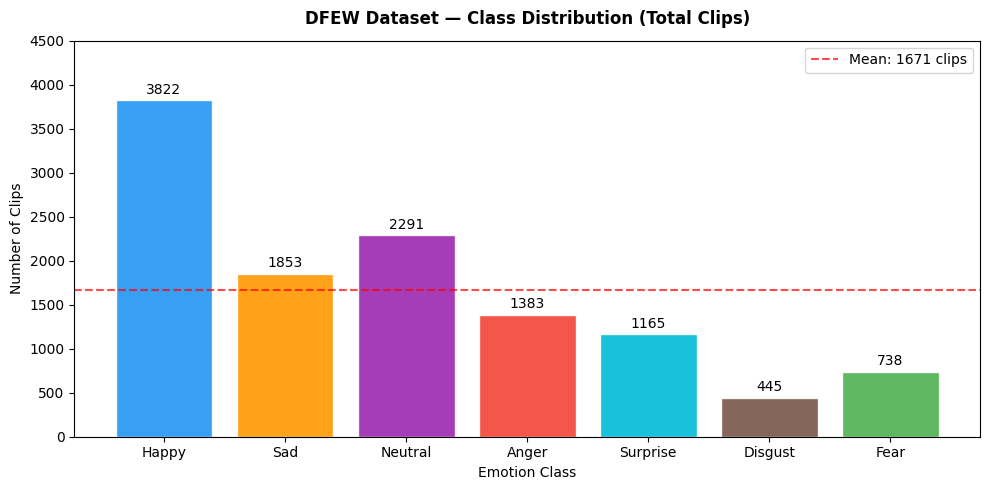

In [1]:
import matplotlib.pyplot as plt
import numpy as np

# From DFEW paper Table 1 — train+test combined
emotions = ['Happy', 'Sad', 'Neutral', 'Anger', 'Surprise', 'Disgust', 'Fear']
counts   = [3822, 1853, 2291, 1383, 1165, 445, 738]  # approximate from paper #11

fig, ax = plt.subplots(figsize=(10, 5))
bars = ax.bar(emotions, counts,
              color=['#2196F3','#FF9800','#9C27B0','#F44336',
                     '#00BCD4','#795548','#4CAF50'],
              edgecolor='white', alpha=0.9)

for bar, count in zip(bars, counts):
    ax.text(bar.get_x() + bar.get_width()/2,
            bar.get_height() + 40,
            str(count), ha='center', va='bottom', fontsize=10)

ax.axhline(np.mean(counts), color='red', linestyle='--',
           linewidth=1.5, alpha=0.7, label=f'Mean: {int(np.mean(counts))} clips')
ax.set_title('DFEW Dataset — Class Distribution (Total Clips)',
             fontweight='bold', pad=12)
ax.set_xlabel('Emotion Class')
ax.set_ylabel('Number of Clips')
ax.legend()
ax.set_ylim(0, 4500)
plt.tight_layout()
plt.savefig('dfew_class_distribution.png', dpi=150, bbox_inches='tight')
plt.show()

In [2]:
import shutil, json, subprocess, os

DATASET_DIR  = '/kaggle/working/dataset_upload'
DATASET_PATH = '/kaggle/input/datasets/faiqhassan98/kd-fer-checkpoints'
DATASET_ID   = 'faiqhassan98/kd-fer-checkpoints'
WORK_DIR     = '/kaggle/working'

os.makedirs(DATASET_DIR, exist_ok=True)

# Clear upload folder
for fname in os.listdir(DATASET_DIR):
    if fname not in ['dataset-metadata.json']:
        try: os.remove(os.path.join(DATASET_DIR, fname))
        except: pass

# Step 1 — accumulate existing dataset files
if os.path.exists(DATASET_PATH):
    for fname in os.listdir(DATASET_PATH):
        if fname.endswith('.pth') or fname.endswith('.png'):
            shutil.copy2(os.path.join(DATASET_PATH, fname),
                         os.path.join(DATASET_DIR, fname))

# Step 2 — add working pth files
for fname in os.listdir(WORK_DIR):
    if fname.endswith('.pth'):
        shutil.copy2(os.path.join(WORK_DIR, fname),
                     os.path.join(DATASET_DIR, fname))

# Step 3 — add the new DFEW distribution chart
if os.path.exists('/kaggle/working/dfew_class_distribution.png'):
    shutil.copy2('/kaggle/working/dfew_class_distribution.png',
                 f'{DATASET_DIR}/dfew_class_distribution.png')
    print("DFEW chart added ✅")
else:
    print("Chart not found — check filename")

total = len([f for f in os.listdir(DATASET_DIR)
             if f.endswith('.pth') or f.endswith('.png')])
print(f"Files queued: {total}")

meta = {"title":"kd-fer-checkpoints","id":DATASET_ID,
        "licenses":[{"name":"CC0-1.0"}]}
with open(f'{DATASET_DIR}/dataset-metadata.json','w') as f:
    json.dump(meta, f)

result = subprocess.run(
    ['kaggle','datasets','version','-p',DATASET_DIR,
     '-m','add dfew class distribution chart','--dir-mode','zip'],
    capture_output=True, text=True, timeout=300)
print("Pushed ✅" if result.returncode==0 else f"Failed ❌\n{result.stderr[:200]}")

DFEW chart added ✅
Files queued: 26
Pushed ✅


In [15]:
#INFERENCE TIME

import torch, time

student.eval()
dummy_input = torch.randn(1, 3, 16, 160, 160).to(device)

# Warmup
for _ in range(10):
    with torch.no_grad():
        _ = student(dummy_input)

# Measure
times = []
for _ in range(100):
    start = time.perf_counter()
    with torch.no_grad():
        _ = student(dummy_input)
    torch.cuda.synchronize()
    times.append(time.perf_counter() - start)

avg_ms = sum(times)/len(times)*1000
print(f"Average inference time: {avg_ms:.2f} ms per clip")

Average inference time: 9.29 ms per clip


In [17]:
import os

# Step 1 — restore from dataset
restore_from_dataset()

# Step 2 — check what files are available
pth_files = [f for f in os.listdir('/kaggle/working/') if f.endswith('.pth')]
print("Available checkpoints:")
for f in sorted(pth_files):
    print(f"  {f}")

Restored 16 checkpoints from dataset ✅
  student_s1_sim1_112.pth
  student_s1_sim1_112_best.pth
  student_s1_sim1_28.pth
  student_s1_sim1_28_best.pth
  student_s1_sim1_56.pth
  student_s1_sim1_56_best.pth
  student_s1_sim2_2f.pth
  student_s1_sim2_2f_best.pth
  student_s1_sim2_4f.pth
  student_s1_sim2_4f_best.pth
  student_s1_sim2_8f.pth
  student_s1_sim2_8f_best.pth
  student_s1_sim3_05.pth
  student_s1_sim3_05_best.pth
  student_s1_sim3_075.pth
  student_s1_sim3_075_best.pth
Available checkpoints:
  student_s1_sim1_112.pth
  student_s1_sim1_112_best.pth
  student_s1_sim1_28.pth
  student_s1_sim1_28_best.pth
  student_s1_sim1_56.pth
  student_s1_sim1_56_best.pth
  student_s1_sim2_2f.pth
  student_s1_sim2_2f_best.pth
  student_s1_sim2_4f.pth
  student_s1_sim2_4f_best.pth
  student_s1_sim2_8f.pth
  student_s1_sim2_8f_best.pth
  student_s1_sim3_05.pth
  student_s1_sim3_05_best.pth
  student_s1_sim3_075.pth
  student_s1_sim3_075_best.pth


In [19]:
import torch, time

device = torch.device('cuda')

student = MobileNetV2GRU(
    num_classes=7, width_mult=1.0,
    gru_hidden=256, num_frames=16, dropout=0.3
).to(device)

# Load any checkpoint — timing does not depend on weights
ckpt = torch.load('/kaggle/working/student_s1_sim1_112_best.pth',
                  map_location=device, weights_only=False)
student.load_state_dict(ckpt['model'])
student.eval()

dummy = torch.randn(1, 3, 16, 160, 160).to(device)

# Warmup
for _ in range(10):
    with torch.no_grad(): _ = student(dummy)

# Measure
times = []
for _ in range(100):
    start = time.perf_counter()
    with torch.no_grad(): _ = student(dummy)
    torch.cuda.synchronize()
    times.append(time.perf_counter() - start)

avg_ms = sum(times)/len(times)*1000
print(f"Inference time (same for S1, S2, S3): {avg_ms:.2f} ms per clip")
print(f"This applies to all three strategies — same architecture")

Inference time (same for S1, S2, S3): 9.26 ms per clip
This applies to all three strategies — same architecture


In [20]:
import torch, time

device = torch.device('cuda')

# Teacher should already be loaded — if not, load it
teacher = load_teacher(fold=1)
teacher.eval()

dummy = torch.randn(1, 3, 16, 160, 160).to(device)

# Warmup
for _ in range(10):
    with torch.no_grad(): _ = teacher(dummy)

# Measure
times = []
for _ in range(100):
    start = time.perf_counter()
    with torch.no_grad(): _ = teacher(dummy)
    torch.cuda.synchronize()
    times.append(time.perf_counter() - start)

avg_ms = sum(times)/len(times)*1000
print(f"Teacher inference time: {avg_ms:.2f} ms per clip")
print(f"Student inference time: 9.26 ms per clip")
print(f"Speedup: {avg_ms/9.26:.1f}x faster")

==> Note: Use 'local_global' for compute reduction (lg_region_size=(2, 5, 10),lg_first_attn_type=self, lg_third_attn_type=cross,lg_attn_param_sharing_first_third=False,lg_attn_param_sharing_all=False,lg_classify_token_type=org,lg_no_second=False, lg_no_third=False)
==> Number of local regions: 8 (size=[4, 2, 1])
Teacher loaded — fold 1 ✅  (84.9M params)
Teacher inference time: 42.10 ms per clip
Student inference time: 9.26 ms per clip
Speedup: 4.5x faster
